In [7]:
# =============================================================================
# PSTH Figure Generation Code
# 根据神经元spike数据绘制PSTH分析图（共三组面板A/B/C）
# 数据路径：D:\在体数据预处理\术前\neuronspiketimelfp\psth_simulated_data_csv
# 依赖库：matplotlib, numpy, pandas, scipy
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.ticker as ticker
from scipy.ndimage import gaussian_filter1d
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('default')          # ← 新增：强制使用默认样式
matplotlib.rcParams['figure.facecolor'] = 'white'   # ← 新增：白色图形背景
matplotlib.rcParams['axes.facecolor']  = 'white'    # ← 新增：白色坐标轴背景
# 图片保存路径
FIGURE_SAVE_DIR = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\psth_In_sd_data_csv3-5"
os.makedirs(FIGURE_SAVE_DIR, exist_ok=True)

def fig_path(filename):
    """返回图片完整保存路径。"""
    return os.path.join(FIGURE_SAVE_DIR, filename)


In [8]:
# ──────────────────────────────────────────────────────────────────────────────
# 【全局字体设置】使用 Times New Roman，可在此统一修改字体
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.ticker as ticker
from scipy.ndimage import gaussian_filter1d
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('default')          # ← 新增：强制使用默认样式
matplotlib.rcParams['figure.facecolor'] = 'white'   # ← 新增：白色图形背景
matplotlib.rcParams['axes.facecolor']  = 'white'    # ← 新增：白色坐标轴背景
# ──────────────────────────────────────────────────────────────────────────────
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['font.serif'] = ['Times New Roman']
matplotlib.rcParams['mathtext.fontset'] = 'stix'   # 数学公式字体与 Times 匹配
matplotlib.rcParams['axes.unicode_minus'] = False

# =============================================================================

In [9]:

# 【数据路径设置】修改此处以适配本地路径
# =============================================================================
DATA_DIR = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\psth_In_sd_data_csv3-5"

SPIKE_FILE        = DATA_DIR + r"\spike_events_long.csv"
FIRING_RATE_FILE  = DATA_DIR + r"\psth_binned_firing_rates.csv"
SUMMARY_FILE      = DATA_DIR + r"\summary_psth_curves.csv"
METADATA_FILE     = DATA_DIR + r"\unit_metadata.csv"

# =============================================================================
# 【加载数据】
# =============================================================================
df_spikes   = pd.read_csv(SPIKE_FILE)
df_fr       = pd.read_csv(FIRING_RATE_FILE)
df_summary  = pd.read_csv(SUMMARY_FILE)
df_meta     = pd.read_csv(METADATA_FILE)




In [10]:
# =============================================================================
# 据实际数据自动判断小鼠数量与每只小鼠记录单元数
# =============================================================================
# 优先用 metadata 统计；若 metadata 缺失某些 unit，则从 firing-rate 数据补充
if {"mouse_id", "unit_id"}.issubset(df_meta.columns):
    _meta_units = df_meta[["mouse_id", "unit_id"]].drop_duplicates().copy()
else:
    _meta_units = pd.DataFrame(columns=["mouse_id", "unit_id"])
_fr_units = df_fr[["mouse_id", "unit_id"]].drop_duplicates().copy()
_actual_units = (
    pd.concat([_meta_units, _fr_units], ignore_index=True)
    .dropna(subset=["mouse_id", "unit_id"])
    .drop_duplicates()
)
# 小鼠顺序：若 metadata 中有排序列则按实际顺序，否则按名称排序
if "mouse_index" in df_meta.columns:
    MOUSE_LIST = (
        df_meta[["mouse_id", "mouse_index"]]
        .drop_duplicates()
        .sort_values("mouse_index")["mouse_id"]
        .tolist()
    )
elif "global_unit_index" in df_meta.columns:
    MOUSE_LIST = (
        df_meta[["mouse_id", "global_unit_index"]]
        .dropna()
        .sort_values("global_unit_index")["mouse_id"]
        .drop_duplicates()
        .tolist()
    )
else:
    MOUSE_LIST = sorted(
        _actual_units["mouse_id"].dropna().unique().tolist()
    )
UNIT_COUNTS_BY_MOUSE = (
    _actual_units.groupby("mouse_id")["unit_id"]
    .nunique()
    .reindex(MOUSE_LIST)
    .fillna(0)
    .astype(int)
)
N_MICE = len(MOUSE_LIST)
N_UNITS_TOTAL = int(UNIT_COUNTS_BY_MOUSE.sum())
print(f"实际检测到：{N_MICE} 只小鼠，{N_UNITS_TOTAL} 个记录单元")
print("每只小鼠记录单元数：", UNIT_COUNTS_BY_MOUSE.to_dict())
print("\n可选小鼠：")
print(MOUSE_LIST)

print("\n可选 unit：")
print(
    _actual_units
    .sort_values(["mouse_id", "unit_id"])
    .to_string(index=False)
)

实际检测到：6 只小鼠，45 个记录单元
每只小鼠记录单元数： {'Mouse_1': 9, 'Mouse_2': 8, 'Mouse_3': 6, 'Mouse_4': 8, 'Mouse_5': 7, 'Mouse_6': 7}

可选小鼠：
['Mouse_1', 'Mouse_2', 'Mouse_3', 'Mouse_4', 'Mouse_5', 'Mouse_6']

可选 unit：
mouse_id unit_id
 Mouse_1 M1_U001
 Mouse_1 M1_U002
 Mouse_1 M1_U003
 Mouse_1 M1_U004
 Mouse_1 M1_U005
 Mouse_1 M1_U006
 Mouse_1 M1_U007
 Mouse_1 M1_U008
 Mouse_1 M1_U009
 Mouse_2 M2_U001
 Mouse_2 M2_U002
 Mouse_2 M2_U003
 Mouse_2 M2_U004
 Mouse_2 M2_U005
 Mouse_2 M2_U006
 Mouse_2 M2_U007
 Mouse_2 M2_U008
 Mouse_3 M3_U001
 Mouse_3 M3_U002
 Mouse_3 M3_U003
 Mouse_3 M3_U004
 Mouse_3 M3_U005
 Mouse_3 M3_U006
 Mouse_4 M4_U001
 Mouse_4 M4_U002
 Mouse_4 M4_U003
 Mouse_4 M4_U004
 Mouse_4 M4_U005
 Mouse_4 M4_U006
 Mouse_4 M4_U007
 Mouse_4 M4_U008
 Mouse_5 M5_U001
 Mouse_5 M5_U002
 Mouse_5 M5_U003
 Mouse_5 M5_U004
 Mouse_5 M5_U005
 Mouse_5 M5_U006
 Mouse_5 M5_U007
 Mouse_6 M6_U001
 Mouse_6 M6_U002
 Mouse_6 M6_U003
 Mouse_6 M6_U004
 Mouse_6 M6_U005
 Mouse_6 M6_U006
 Mouse_6 M6_U007


In [12]:
# =============================================================================
# 指定 Panel A/B 使用的小鼠和 unit
# =============================================================================
# 是否手动指定
# True  = 手动指定 Panel A/B 的小鼠和 unit
# False = 自动选择第一只有 unit 的小鼠及其第一个 unit
USE_MANUAL_SELECTION = True
if USE_MANUAL_SELECTION:
    # =========================================================
    # 在这里修改你感兴趣的小鼠和神经元#按照需要修改
    # =========================================================
    DEFAULT_MOUSE_ID = "Mouse_4"
    DEFAULT_UNIT_ID  = "M4_U001"
else:
    # 自动选择第一只有 unit 的小鼠
    DEFAULT_MOUSE_ID = UNIT_COUNTS_BY_MOUSE[
        UNIT_COUNTS_BY_MOUSE > 0
    ].index[0]
    # 自动选择该小鼠的第一个 unit
    if {"mouse_id", "unit_index_within_mouse", "unit_id"}.issubset(df_meta.columns):
        DEFAULT_UNIT_ID = (
            df_meta[df_meta["mouse_id"] == DEFAULT_MOUSE_ID]
            .sort_values("unit_index_within_mouse")["unit_id"]
            .iloc[0]
        )
    else:
        DEFAULT_UNIT_ID = sorted(
            _actual_units[
                _actual_units["mouse_id"] == DEFAULT_MOUSE_ID
            ]["unit_id"].unique()
        )[0]

# 检查选择是否存在
_selected = _actual_units[
    (_actual_units["mouse_id"] == DEFAULT_MOUSE_ID) &
    (_actual_units["unit_id"] == DEFAULT_UNIT_ID)
]

if _selected.empty:
    raise ValueError(
        f"未找到指定单元：mouse_id={DEFAULT_MOUSE_ID}, unit_id={DEFAULT_UNIT_ID}"
    )

print(f"Panel A/B 当前使用：{DEFAULT_MOUSE_ID} | {DEFAULT_UNIT_ID}")


Panel A/B 当前使用：Mouse_4 | M4_U001


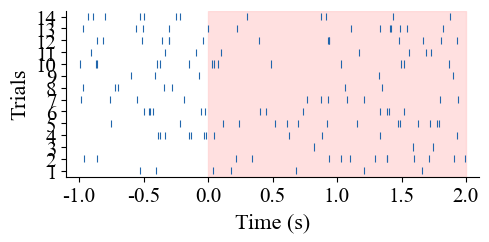

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U001.pdf


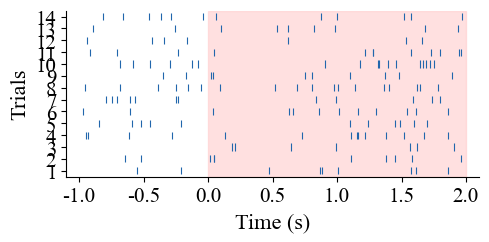

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U002.pdf


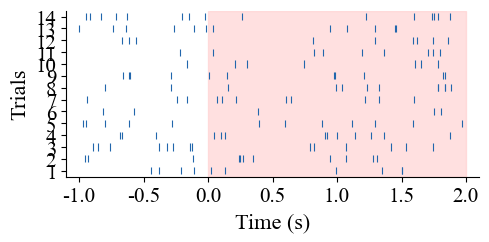

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U003.pdf


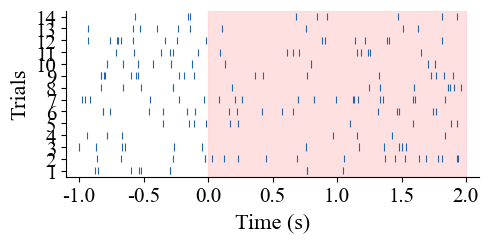

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U004.pdf


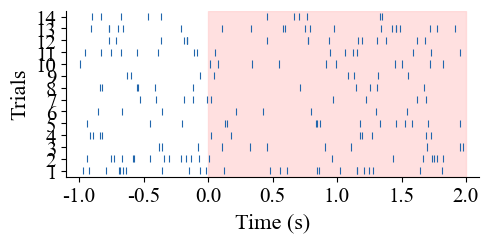

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U005.pdf


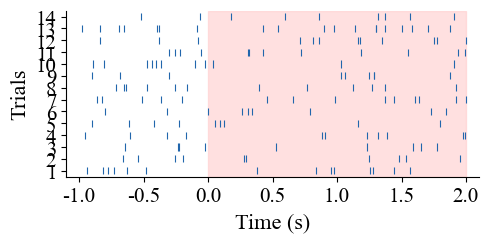

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U006.pdf


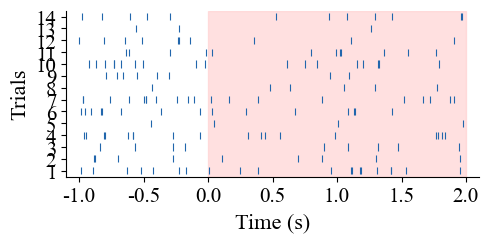

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U007.pdf


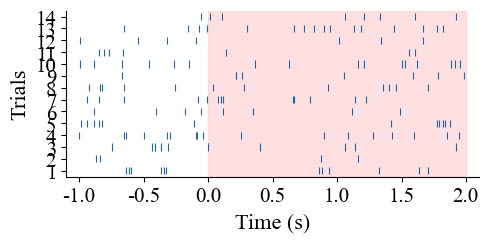

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U008.pdf


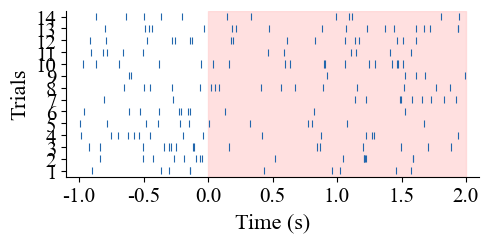

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_1_M1_U009.pdf


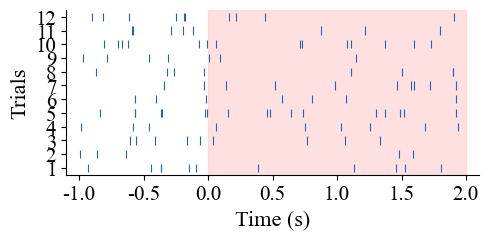

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U001.pdf


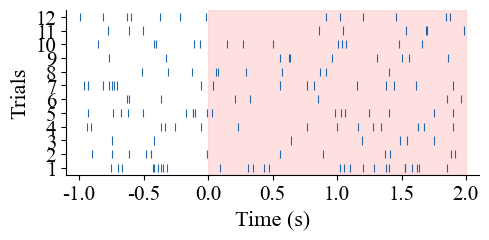

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U002.pdf


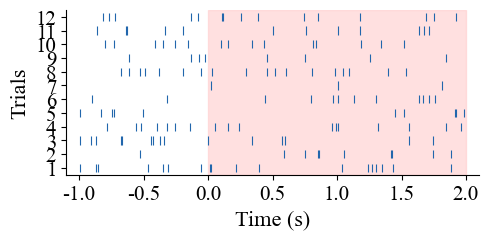

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U003.pdf


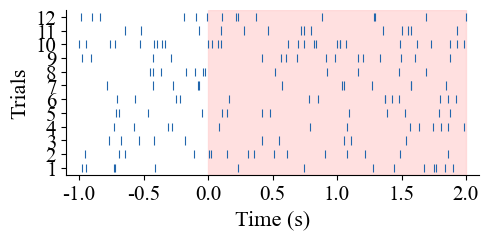

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U004.pdf


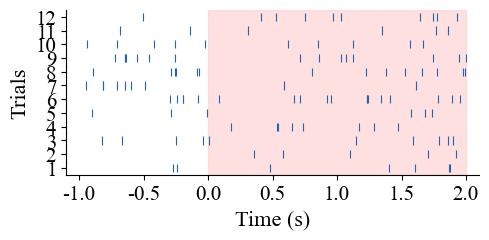

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U005.pdf


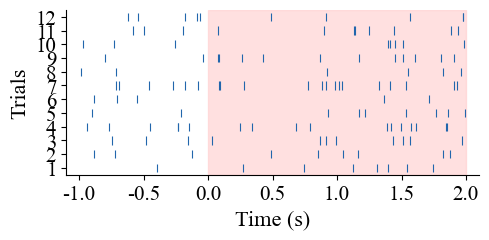

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U006.pdf


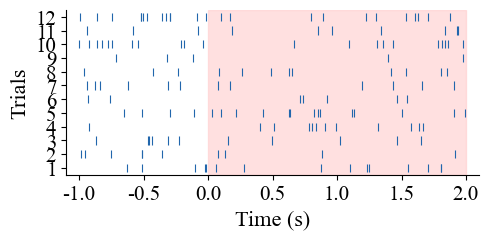

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U007.pdf


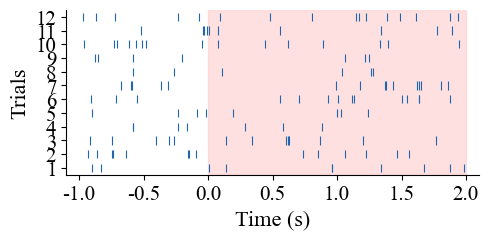

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_2_M2_U008.pdf


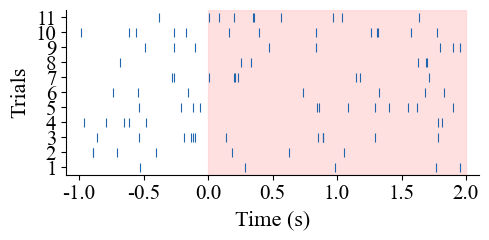

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_3_M3_U001.pdf


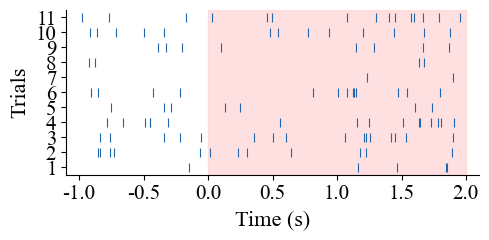

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_3_M3_U002.pdf


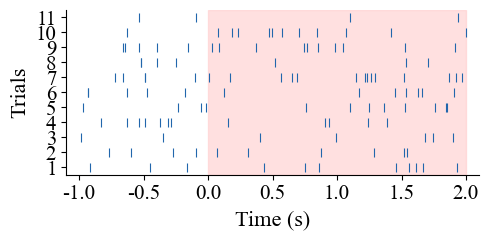

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_3_M3_U003.pdf


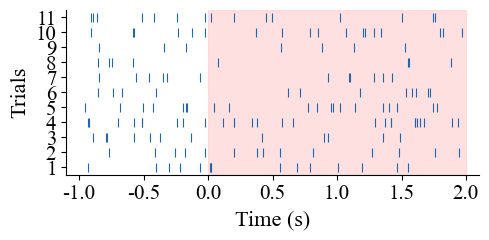

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_3_M3_U004.pdf


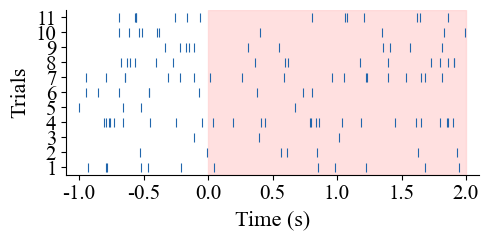

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_3_M3_U005.pdf


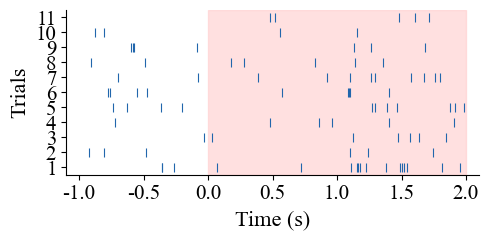

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_3_M3_U006.pdf


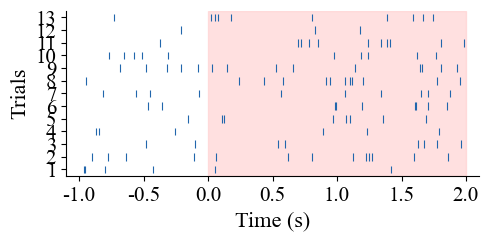

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U001.pdf


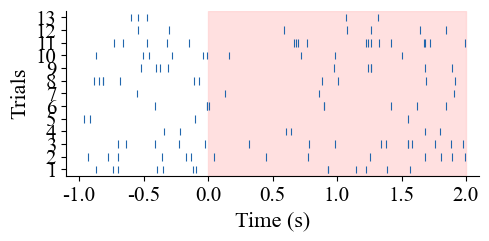

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U002.pdf


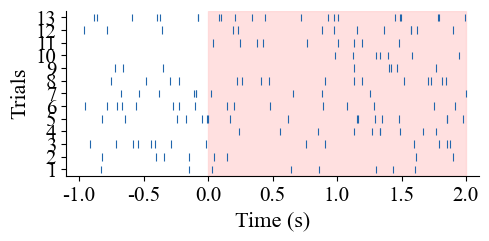

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U003.pdf


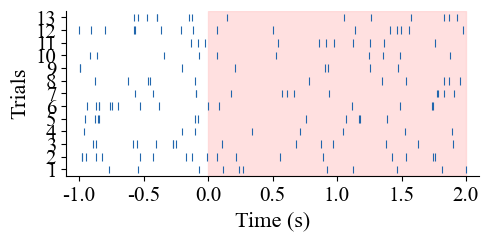

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U004.pdf


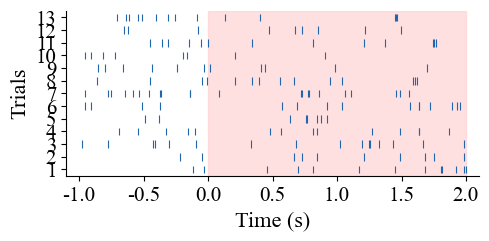

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U005.pdf


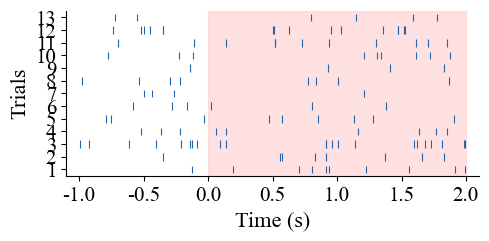

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U006.pdf


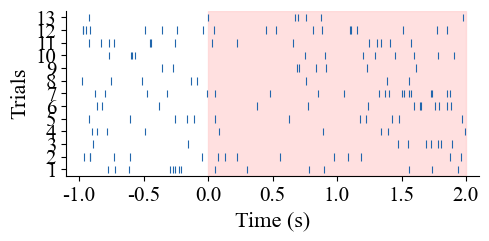

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U007.pdf


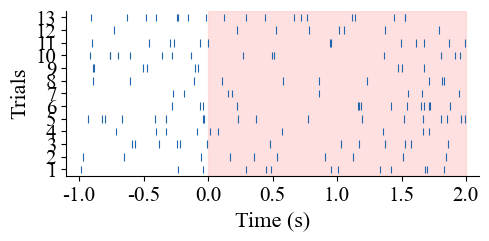

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_4_M4_U008.pdf


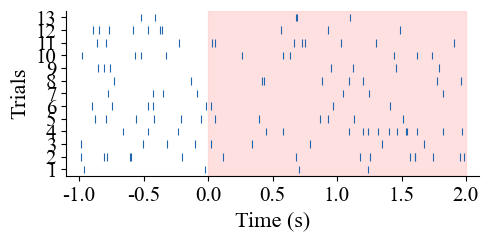

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U001.pdf


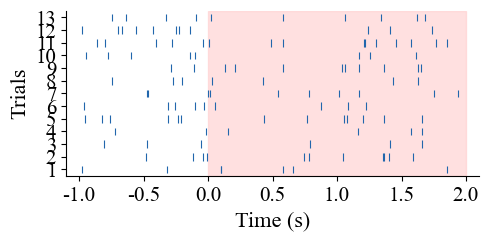

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U002.pdf


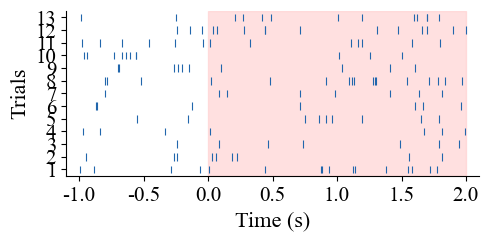

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U003.pdf


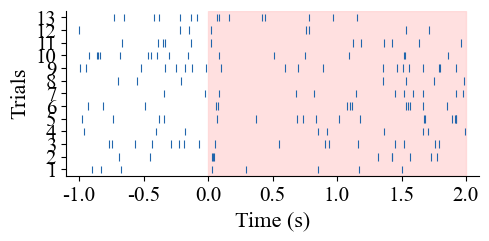

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U004.pdf


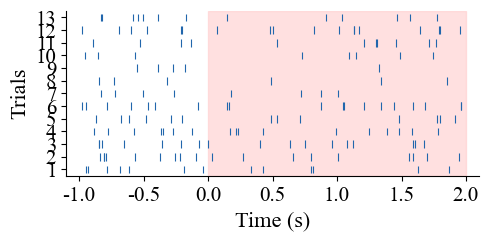

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U005.pdf


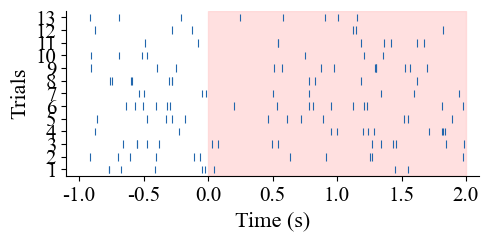

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U006.pdf


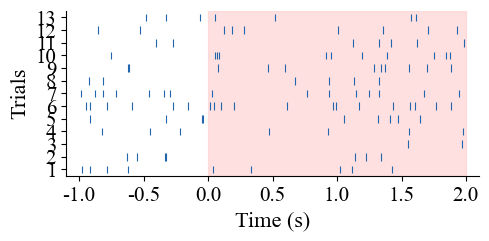

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_5_M5_U007.pdf


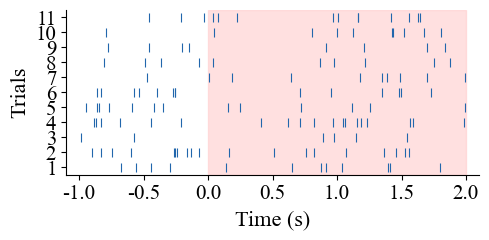

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U001.pdf


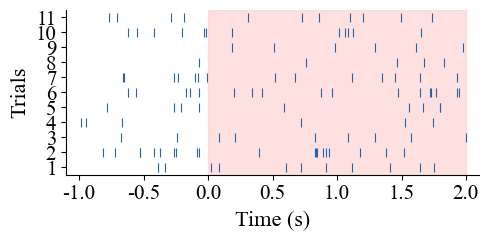

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U002.pdf


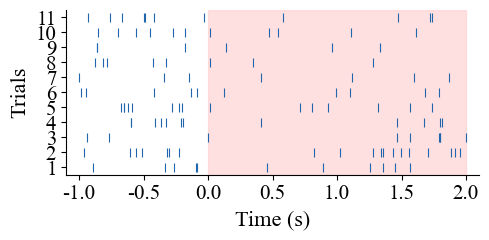

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U003.pdf


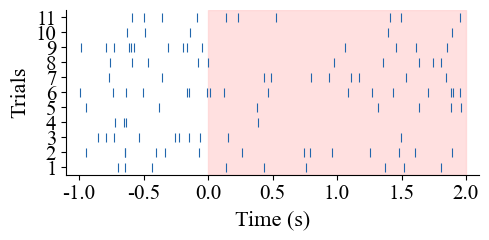

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U004.pdf


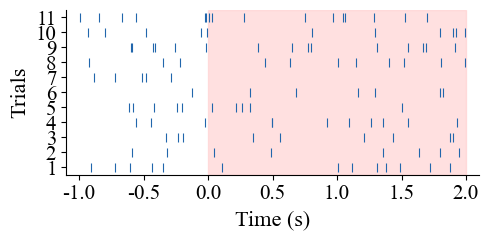

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U005.pdf


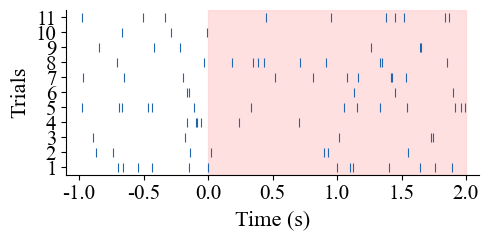

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U006.pdf


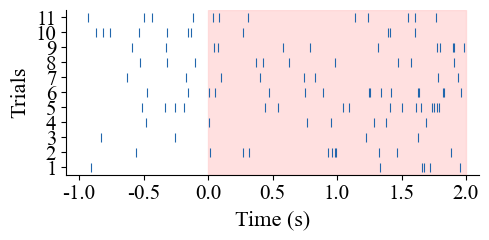

✅ Panel A Raster 已保存：Panel_A_Raster_Mouse_6_M6_U007.pdf


In [13]:
# =============================================================================
# ██████████████████████████████████████████████████████████████████████████████
# 单元 1：Panel A 上图 —— 所有小鼠、所有神经元 Raster Plot（点阵图）
#          图片高度随 trial 数自动调整
# ██████████████████████████████████████████████████████████████████████████████
# =============================================================================

# ---【参数区：可在此自定义】---
RASTER_XLIM          = (-1.1, 2.1)
RASTER_YLIM          = None          # None = 自动
RASTER_TICK_X        = 0.5
RASTER_SPIKE_COLOR   = "#2166ac"
RASTER_SPIKE_HEIGHT  = 0.6
RASTER_SPIKE_LW      = 0.8
RASTER_STIM_COLOR    = "#ffcccc"
RASTER_STIM_ALPHA    = 0.6
STIM_ONSET           = 0.0
STIM_OFFSET          = 2.0
RASTER_LABEL_FONTSIZE = 16
RASTER_TICK_FONTSIZE  = 15
RASTER_TITLE_FONTSIZE = 17

# ---【遍历所有小鼠和所有单元】---
for _mouse_id in MOUSE_LIST:
    _units = sorted(
        _actual_units[_actual_units["mouse_id"] == _mouse_id]["unit_id"].unique()
    )
    for _unit_id in _units:
        df_A = df_spikes[
            (df_spikes["mouse_id"] == _mouse_id) &
            (df_spikes["unit_id"]  == _unit_id)
        ].copy()

        raster_trials = sorted(df_A["trial"].dropna().unique())
        n_trials = len(raster_trials)

        # ---【图片高度随 trial 数自动调整】---
        fig_h = max(2.5, n_trials * 0.18)

        fig_A_raster, ax = plt.subplots(figsize=(5, fig_h))

        ax.axvspan(STIM_ONSET, STIM_OFFSET,
                   color=RASTER_STIM_COLOR, alpha=RASTER_STIM_ALPHA, zorder=0)

        for trial_id, grp in df_A.groupby("trial"):
            for t in grp["spike_time_s"]:
                ax.vlines(t,
                          trial_id - RASTER_SPIKE_HEIGHT / 2,
                          trial_id + RASTER_SPIKE_HEIGHT / 2,
                          color=RASTER_SPIKE_COLOR,
                          linewidth=RASTER_SPIKE_LW)

        ax.set_xlim(RASTER_XLIM)
        _ylim = (min(raster_trials) - 0.5, max(raster_trials) + 0.5) \
                if raster_trials else (0.5, 1.5)
        ax.set_ylim(_ylim)
        ax.set_xlabel("Time (s)", fontsize=RASTER_LABEL_FONTSIZE)
        ax.set_ylabel("Trials",   fontsize=RASTER_LABEL_FONTSIZE)
        #ax.set_title(
        #    f"Single mouse, representative unit",
        #    fontsize=RASTER_TITLE_FONTSIZE, fontweight="bold"
        #)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(RASTER_TICK_X))
        ax.tick_params(axis='both', labelsize=RASTER_TICK_FONTSIZE)
        ax.set_yticks(raster_trials if raster_trials else [])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        plt.tight_layout()
        _fname = f"Panel_A_Raster_{_mouse_id}_{_unit_id}.pdf"
        plt.savefig(fig_path(_fname), dpi=300, bbox_inches='tight')
        plt.show()
        print(f"✅ Panel A Raster 已保存：{_fname}")


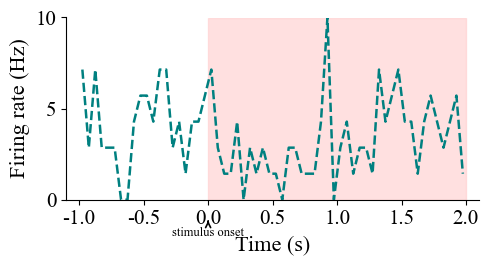

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U001.pdf


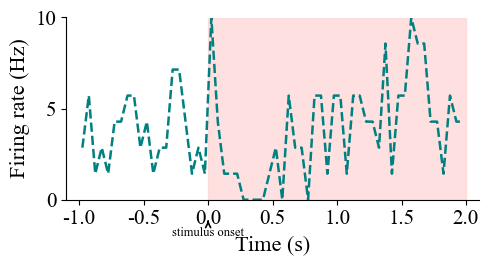

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U002.pdf


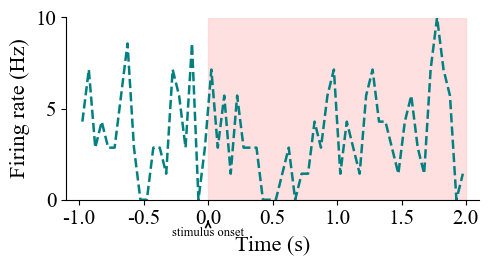

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U003.pdf


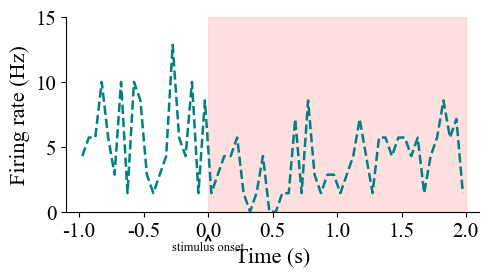

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U004.pdf


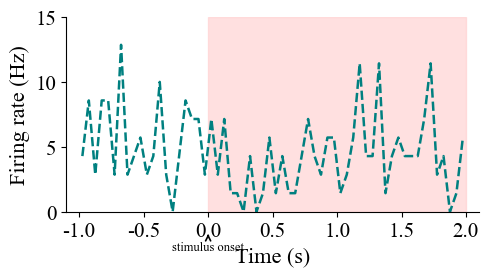

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U005.pdf


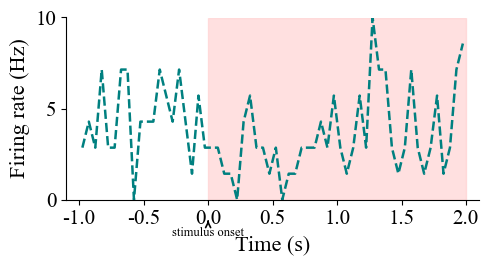

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U006.pdf


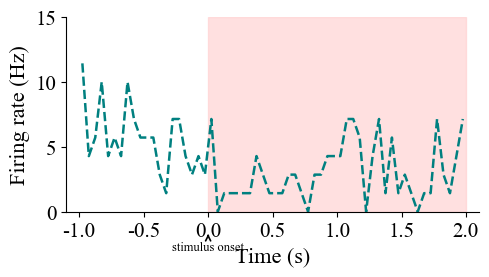

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U007.pdf


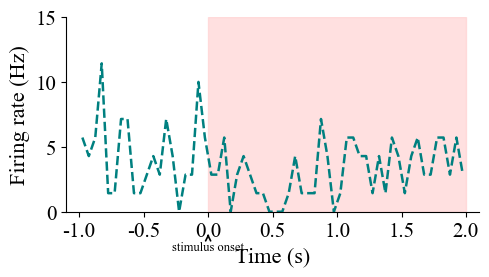

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U008.pdf


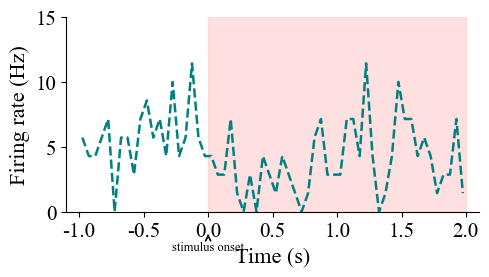

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_1_M1_U009.pdf


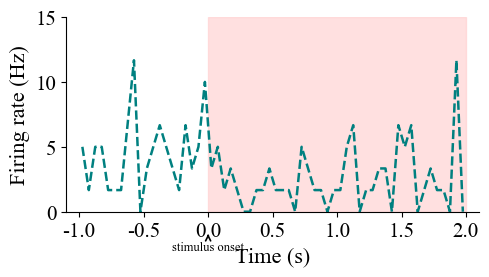

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U001.pdf


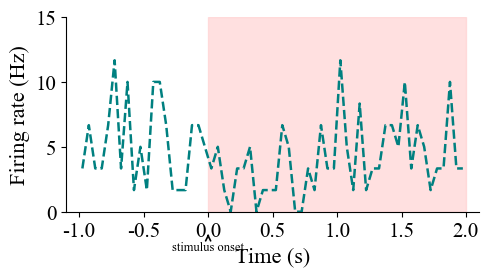

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U002.pdf


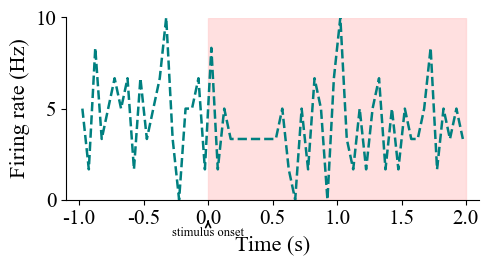

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U003.pdf


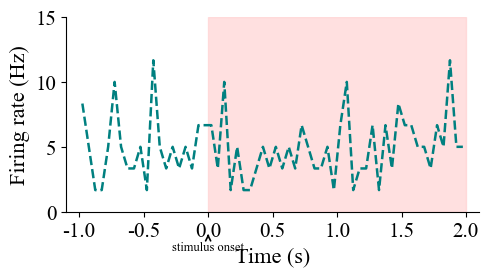

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U004.pdf


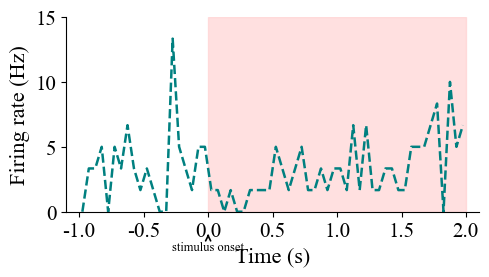

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U005.pdf


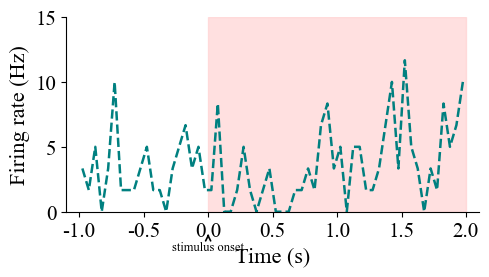

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U006.pdf


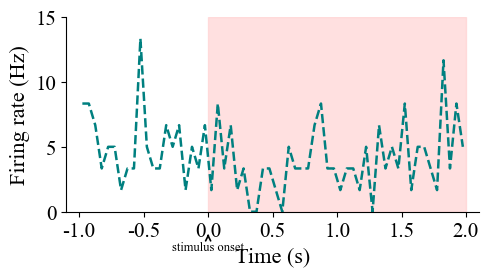

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U007.pdf


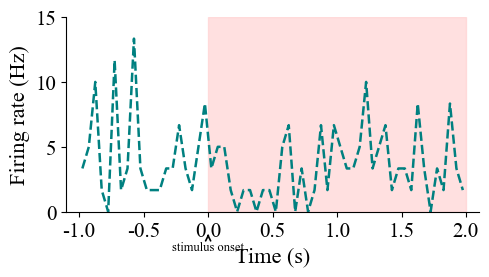

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_2_M2_U008.pdf


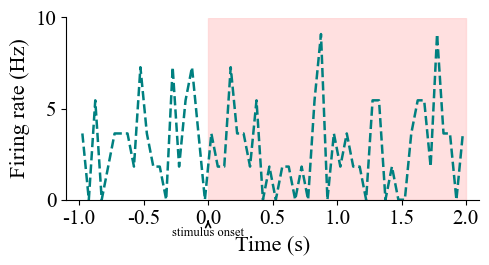

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_3_M3_U001.pdf


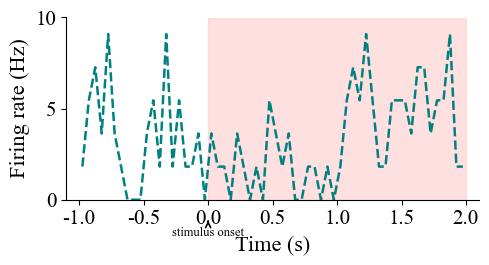

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_3_M3_U002.pdf


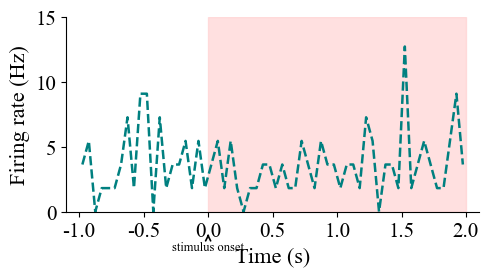

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_3_M3_U003.pdf


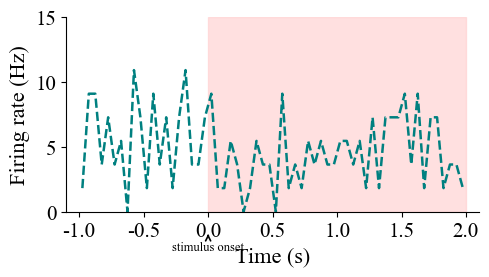

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_3_M3_U004.pdf


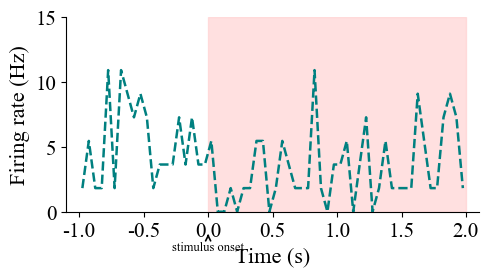

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_3_M3_U005.pdf


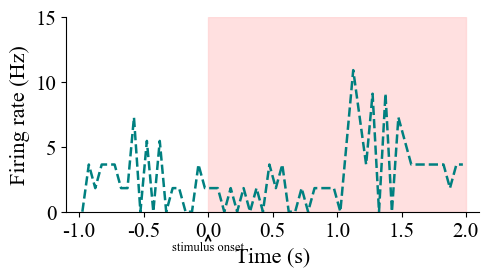

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_3_M3_U006.pdf


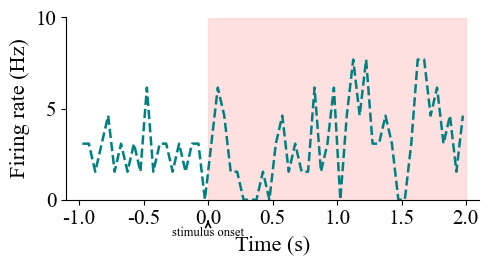

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U001.pdf


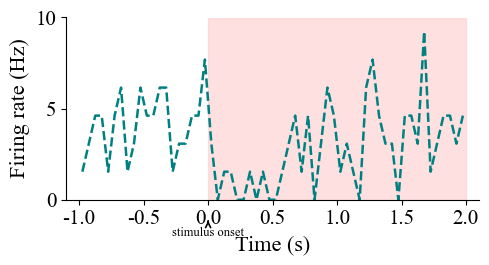

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U002.pdf


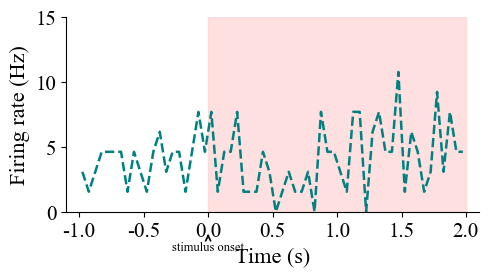

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U003.pdf


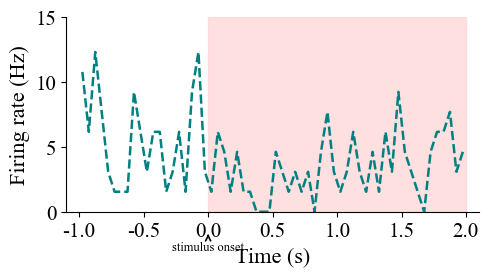

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U004.pdf


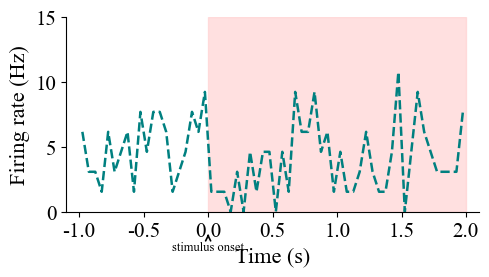

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U005.pdf


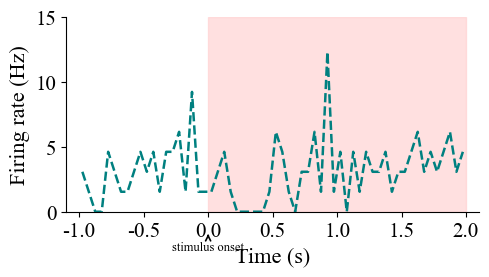

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U006.pdf


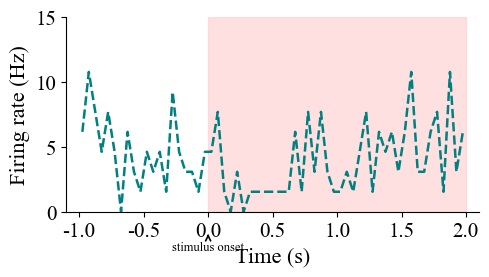

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U007.pdf


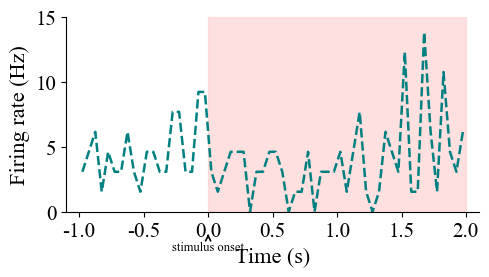

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_4_M4_U008.pdf


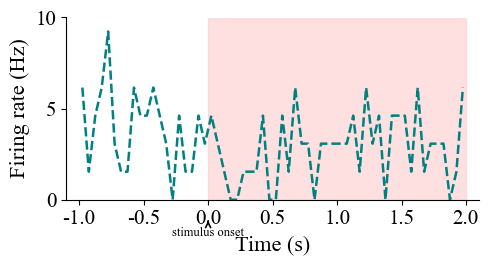

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U001.pdf


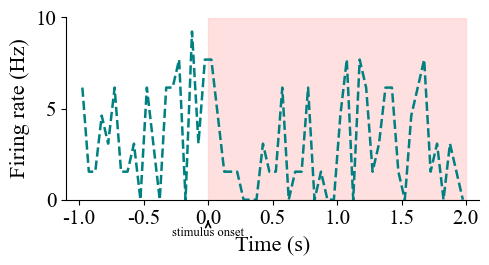

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U002.pdf


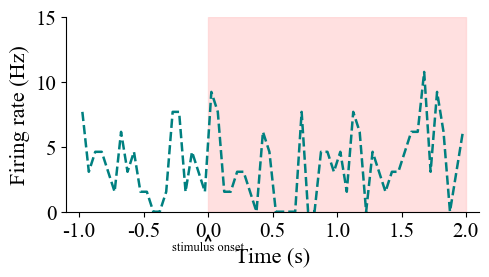

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U003.pdf


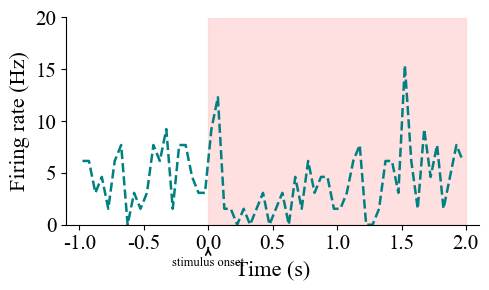

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U004.pdf


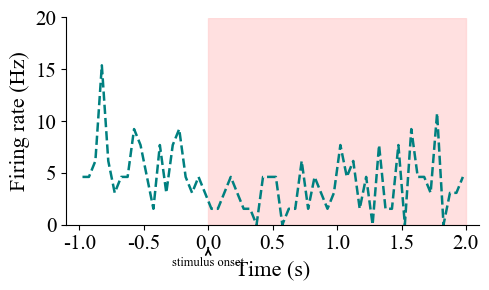

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U005.pdf


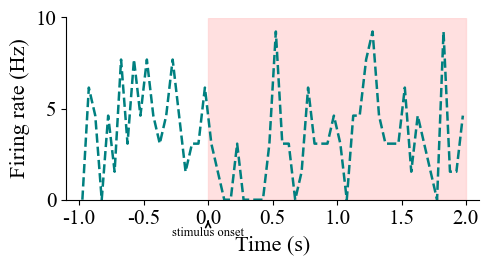

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U006.pdf


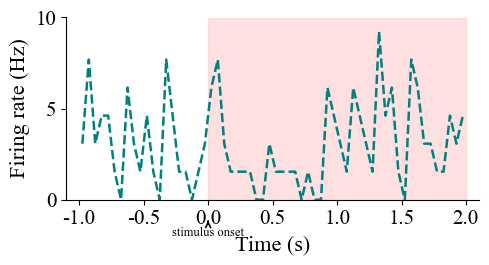

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_5_M5_U007.pdf


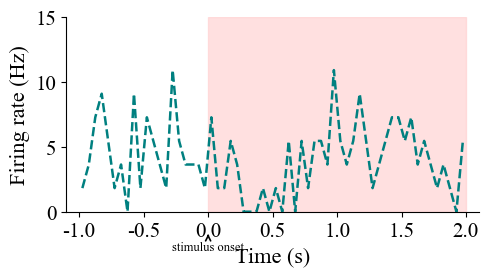

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U001.pdf


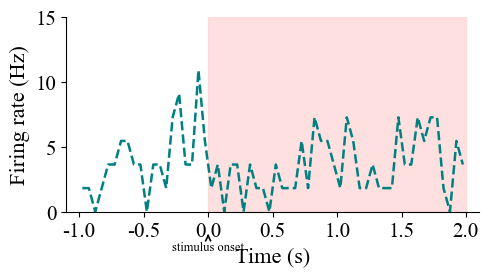

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U002.pdf


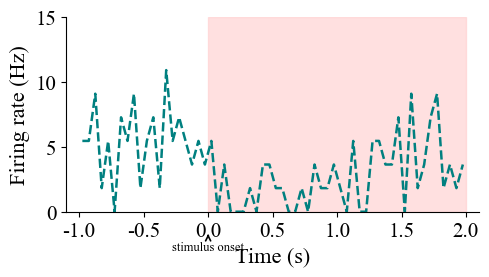

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U003.pdf


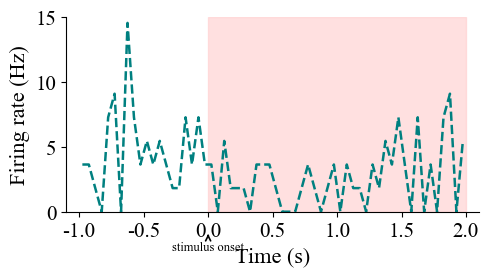

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U004.pdf


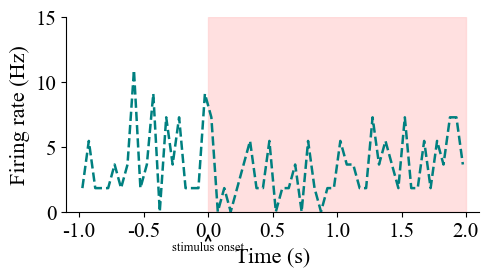

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U005.pdf


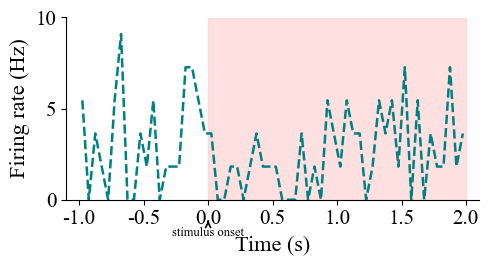

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U006.pdf


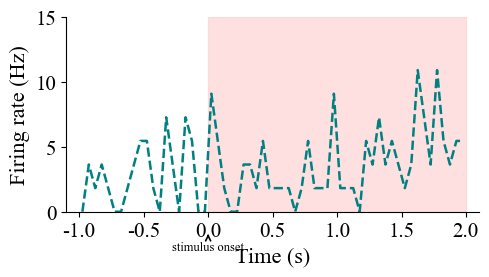

✅ Panel A PSTH 已保存：Panel_A_PSTH_Mouse_6_M6_U007.pdf


In [14]:
# =============================================================================
# ██████████████████████████████████████████████████████████████████████████████
# 单元 2：Panel A 下图 —— 所有小鼠、所有神经元 PSTH 曲线
#          图片高度随数据自动调整
# ██████████████████████████████████████████████████████████████████████████████
# =============================================================================

# ---【参数区：可在此自定义】---
PSTH_A_XLIM        = (-1.1, 2.1)
PSTH_A_YLIM        = (0, 10)
PSTH_A_TICK_X      = 0.5
PSTH_A_TICK_Y      = 5
PSTH_A_LINE_COLOR  = "#008080"
PSTH_A_LINE_WIDTH  = 1.8
PSTH_A_LINE_STYLE  = "--"
PSTH_A_SMOOTH_SIGMA = 0
PSTH_A_STIM_COLOR  = "#ffcccc"
PSTH_A_STIM_ALPHA  = 0.6
PSTH_A_LABEL_FONTSIZE = 16
PSTH_A_TICK_FONTSIZE  = 15
PSTH_A_TITLE_FONTSIZE = 17

# ---【遍历所有小鼠和所有单元】---
for _mouse_id in MOUSE_LIST:
    _units = sorted(
        _actual_units[_actual_units["mouse_id"] == _mouse_id]["unit_id"].unique()
    )
    for _unit_id in _units:
        df_summary_A = df_fr[
            (df_fr["mouse_id"] == _mouse_id) &
            (df_fr["unit_id"]  == _unit_id)
        ].sort_values("time_bin_center_s")

        t_A  = df_summary_A["time_bin_center_s"].values
        fr_A = df_summary_A["firing_rate_hz"].values
        if PSTH_A_SMOOTH_SIGMA > 0:
            fr_A = gaussian_filter1d(fr_A, sigma=PSTH_A_SMOOTH_SIGMA)

        # ---【图片高度随数据范围自动调整（y 轴动态上限）】---
        _fr_max = fr_A.max() if len(fr_A) > 0 else 20
        _ylim_top = max(PSTH_A_YLIM[1], float(np.ceil(_fr_max / 5) * 5))
        _ylim = (PSTH_A_YLIM[0], _ylim_top)
        _y_range = _ylim_top - _ylim[0]
        fig_h = max(2.5, 2.5 + _y_range / 40)

        fig_A_psth, ax = plt.subplots(figsize=(5, fig_h))

        ax.axvspan(STIM_ONSET, STIM_OFFSET,
                   color=PSTH_A_STIM_COLOR, alpha=PSTH_A_STIM_ALPHA, zorder=0)
        ax.plot(t_A, fr_A,
                color=PSTH_A_LINE_COLOR,
                linewidth=PSTH_A_LINE_WIDTH,
                linestyle=PSTH_A_LINE_STYLE)

        y_min, y_max = _ylim
        y_range = y_max - y_min
        arrow_tip_y  = y_min - y_range * 0.10
        arrow_text_y = y_min - y_range * 0.20
        ax.annotate("stimulus onset",
                    xy=(STIM_ONSET, arrow_tip_y),
                    xytext=(STIM_ONSET, arrow_text_y),
                    fontsize=9, ha='center',
                    arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
                    annotation_clip=False)

        ax.set_xlim(PSTH_A_XLIM)
        ax.set_ylim(_ylim)
        ax.set_xlabel("Time (s)",          fontsize=PSTH_A_LABEL_FONTSIZE)
        ax.set_ylabel("Firing rate (Hz)",  fontsize=PSTH_A_LABEL_FONTSIZE)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(PSTH_A_TICK_X))
        ax.yaxis.set_major_locator(ticker.MultipleLocator(PSTH_A_TICK_Y))
        ax.tick_params(axis='both', labelsize=PSTH_A_TICK_FONTSIZE)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        plt.tight_layout()
        _fname = f"Panel_A_PSTH_{_mouse_id}_{_unit_id}.pdf"
        plt.savefig(fig_path(_fname), dpi=300, bbox_inches='tight')
        plt.show()
        print(f"✅ Panel A PSTH 已保存：{_fname}")


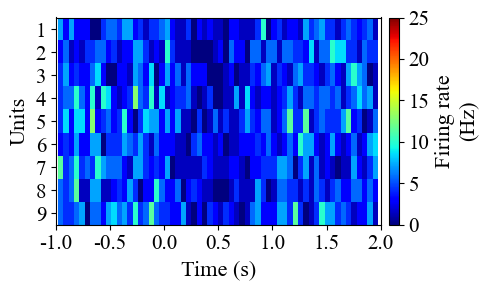

✅ Panel B Heatmap 已保存：Panel_B_Heatmap_Mouse_1.pdf


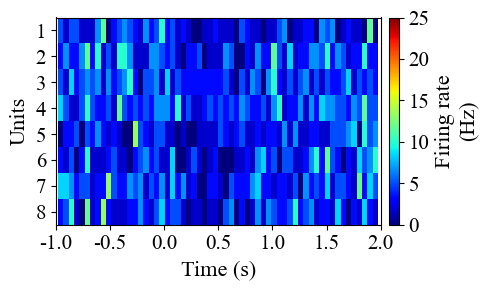

✅ Panel B Heatmap 已保存：Panel_B_Heatmap_Mouse_2.pdf


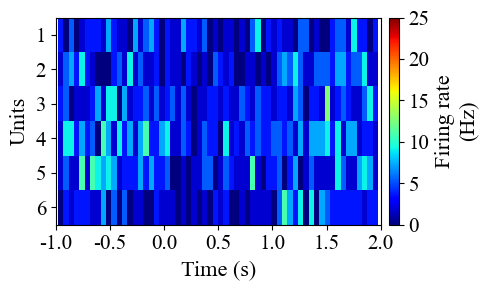

✅ Panel B Heatmap 已保存：Panel_B_Heatmap_Mouse_3.pdf


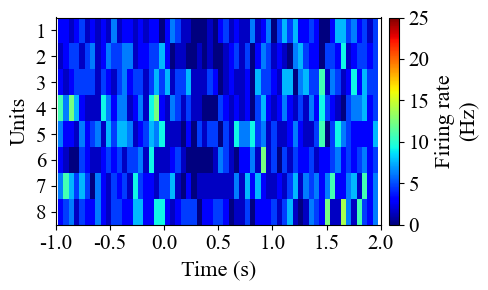

✅ Panel B Heatmap 已保存：Panel_B_Heatmap_Mouse_4.pdf


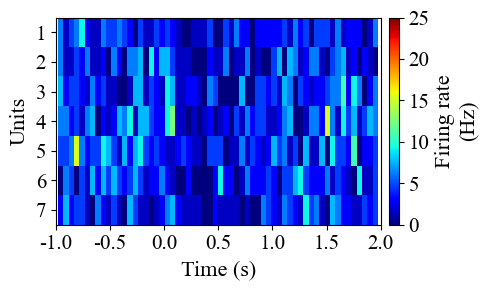

✅ Panel B Heatmap 已保存：Panel_B_Heatmap_Mouse_5.pdf


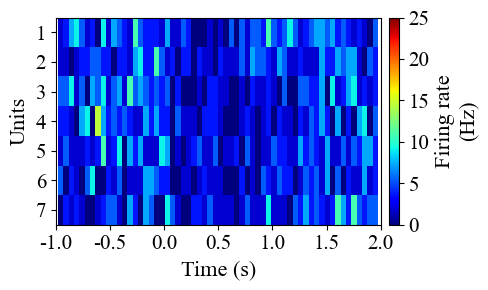

✅ Panel B Heatmap 已保存：Panel_B_Heatmap_Mouse_6.pdf


In [15]:
# =============================================================================
# ██████████████████████████████████████████████████████████████████████████████
# 单元 3：Panel B 上图 —— 所有小鼠 Firing Rate Heatmap（热力图）
#          图片高度随单元数自动调整
# ██████████████████████████████████████████████████████████████████████████████
# =============================================================================

# ---【参数区：可在此自定义】---
HEATMAP_B_XLIM       = (-1.0, 2.0)
HEATMAP_B_VMIN       = 0
HEATMAP_B_VMAX       = 25
HEATMAP_B_CMAP       = "jet"
HEATMAP_B_CBAR_LABEL = "Firing rate\n(Hz)"
HEATMAP_B_TICK_X     = 0.5
HEATMAP_B_LABEL_FONTSIZE = 16
HEATMAP_B_TICK_FONTSIZE  = 15
HEATMAP_B_TITLE_FONTSIZE = 17

# ---【遍历所有小鼠】---
for _mouse_id in MOUSE_LIST:
    df_B = df_fr[df_fr["mouse_id"] == _mouse_id].copy()

    pivot_B = df_B.pivot_table(index="unit_id",
                               columns="time_bin_center_s",
                               values="firing_rate_hz")
    unit_order_B = (df_meta[df_meta["mouse_id"] == _mouse_id]
                    .sort_values("unit_index_within_mouse")["unit_id"].tolist())
    pivot_B = pivot_B.loc[[u for u in unit_order_B if u in pivot_B.index]]
    time_bins_B = pivot_B.columns.values
    matrix_B    = pivot_B.values

    n_units = matrix_B.shape[0]

    # ---【图片高度随单元数自动调整】---
    fig_h = max(3.0, n_units * 0.28)

    fig_B_heat, ax = plt.subplots(figsize=(5, fig_h))

    im = ax.imshow(matrix_B,
                   aspect='auto',
                   origin='upper',
                   vmin=HEATMAP_B_VMIN,
                   vmax=HEATMAP_B_VMAX,
                   cmap=HEATMAP_B_CMAP,
                   extent=[time_bins_B[0], time_bins_B[-1],
                           n_units + 0.5, 0.5])

    cbar = fig_B_heat.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(HEATMAP_B_CBAR_LABEL, fontsize=HEATMAP_B_LABEL_FONTSIZE)
    cbar.ax.tick_params(labelsize=HEATMAP_B_TICK_FONTSIZE)
    cbar.set_ticks([0, 5, 10, 15, 20, 25])

    ax.set_xlim(HEATMAP_B_XLIM)
    ax.set_xlabel("Time (s)", fontsize=HEATMAP_B_LABEL_FONTSIZE)
    ax.set_ylabel("Units",    fontsize=HEATMAP_B_LABEL_FONTSIZE)
    #ax.set_title(
     #   f"multiple units",
       # fontsize=HEATMAP_B_TITLE_FONTSIZE, fontweight="bold"
    #)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(HEATMAP_B_TICK_X))
    ax.tick_params(axis='both', labelsize=HEATMAP_B_TICK_FONTSIZE)

    if n_units <= 10:
        ax.set_yticks(range(1, n_units + 1))
    else:
        ax.set_yticks(
            np.linspace(1, n_units, min(5, n_units)).round().astype(int)
        )

    plt.tight_layout()
    _fname = f"Panel_B_Heatmap_{_mouse_id}.pdf"
    plt.savefig(fig_path(_fname), dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Panel B Heatmap 已保存：{_fname}")


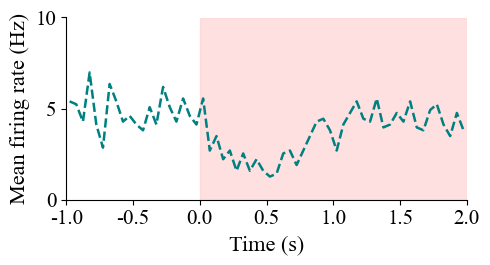

✅ Panel B PSTH 已保存：Panel_B_PSTH_Mouse_1.pdf


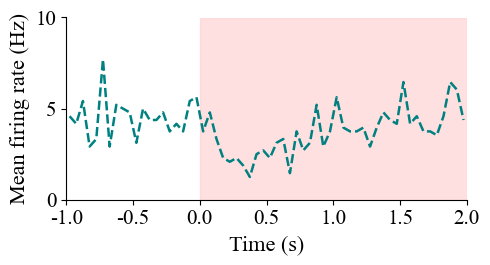

✅ Panel B PSTH 已保存：Panel_B_PSTH_Mouse_2.pdf


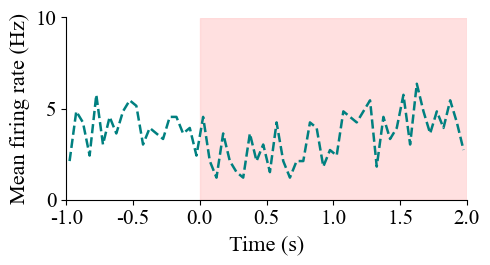

✅ Panel B PSTH 已保存：Panel_B_PSTH_Mouse_3.pdf


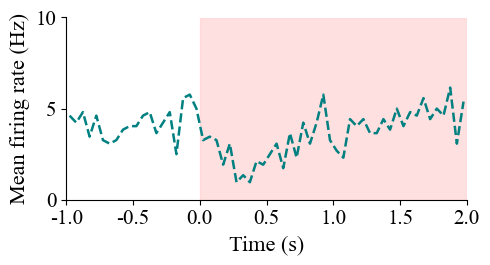

✅ Panel B PSTH 已保存：Panel_B_PSTH_Mouse_4.pdf


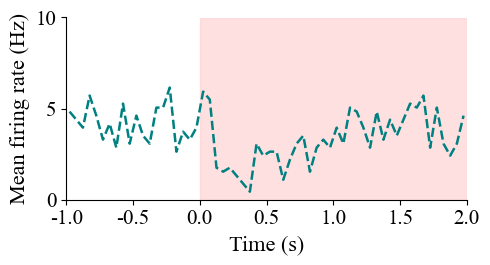

✅ Panel B PSTH 已保存：Panel_B_PSTH_Mouse_5.pdf


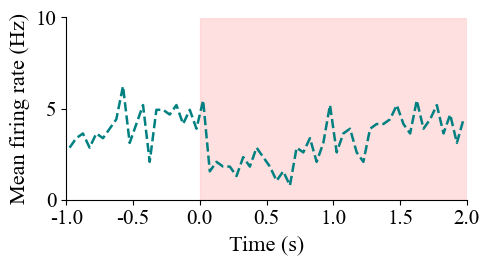

✅ Panel B PSTH 已保存：Panel_B_PSTH_Mouse_6.pdf


In [16]:
# =============================================================================
# ██████████████████████████████████████████████████████████████████████████████
# 单元 4：Panel B 下图 —— 所有小鼠 平均 PSTH 曲线（Mean Firing Rate）
#          图片高度随数据自动调整
# ██████████████████████████████████████████████████████████████████████████████
# =============================================================================

# ---【参数区：可在此自定义】---
PSTH_B_XLIM = (-1.0, 2.0)
PSTH_B_YLIM = (0, 10)
PSTH_B_TICK_X = 0.5
PSTH_B_TICK_Y = 5
PSTH_B_LINE_COLOR = "#008080"
PSTH_B_LINE_WIDTH = 1.8
PSTH_B_LINE_STYLE = "--"
PSTH_B_SMOOTH_SIGMA = 0
PSTH_B_STIM_COLOR = "#ffcccc"
PSTH_B_STIM_ALPHA = 0.6
PSTH_B_LABEL_FONTSIZE = 16
PSTH_B_TICK_FONTSIZE = 15

# ---【遍历所有小鼠】---
for _mouse_id in MOUSE_LIST:
    df_B_mean = (df_fr[df_fr["mouse_id"] == _mouse_id]
                 .groupby("time_bin_center_s", as_index=False)["firing_rate_hz"]
                 .mean()
                 .sort_values("time_bin_center_s"))

    t_B  = df_B_mean["time_bin_center_s"].values
    fr_B = df_B_mean["firing_rate_hz"].values
    if PSTH_B_SMOOTH_SIGMA > 0:
        fr_B = gaussian_filter1d(fr_B, sigma=PSTH_B_SMOOTH_SIGMA)

    # ---【图片高度随 y 轴范围自动调整】---
    _fr_max = fr_B.max() if len(fr_B) > 0 else 10
    _ylim_top = max(PSTH_B_YLIM[1], float(np.ceil(_fr_max / 5) * 5))
    _ylim = (PSTH_B_YLIM[0], _ylim_top)
    _y_range = _ylim_top - _ylim[0]
    fig_h = max(2.5, 2.5 + _y_range / 40)

    fig_B_psth, ax = plt.subplots(figsize=(5, fig_h))

    ax.axvspan(STIM_ONSET, STIM_OFFSET,
               color=PSTH_B_STIM_COLOR, alpha=PSTH_B_STIM_ALPHA, zorder=0)
    ax.plot(t_B, fr_B,
            color=PSTH_B_LINE_COLOR,
            linewidth=PSTH_B_LINE_WIDTH,
            linestyle=PSTH_B_LINE_STYLE)

    y_min, y_max = _ylim
    y_range = y_max - y_min
    arrow_tip_y  = y_min - y_range * 0.10
    arrow_text_y = y_min - y_range * 0.20
    #ax.annotate("stimulus onset",
     #           xy=(STIM_ONSET, arrow_tip_y),
       #         xytext=(STIM_ONSET, arrow_text_y),
         #       fontsize=14, ha='center',
           #     arrowprops=dict(arrowstyle='->', color='black', lw=1.8),
           #     annotation_clip=False)

    ax.set_xlim(PSTH_B_XLIM)
    ax.set_ylim(_ylim)
    ax.set_xlabel("Time (s)",             fontsize=PSTH_B_LABEL_FONTSIZE)
    ax.set_ylabel("Mean firing rate (Hz)", fontsize=PSTH_B_LABEL_FONTSIZE)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(PSTH_B_TICK_X))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(PSTH_B_TICK_Y))
    ax.tick_params(axis='both', labelsize=PSTH_B_TICK_FONTSIZE)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    _fname = f"Panel_B_PSTH_{_mouse_id}.pdf"
    plt.savefig(fig_path(_fname), dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Panel B PSTH 已保存：{_fname}")


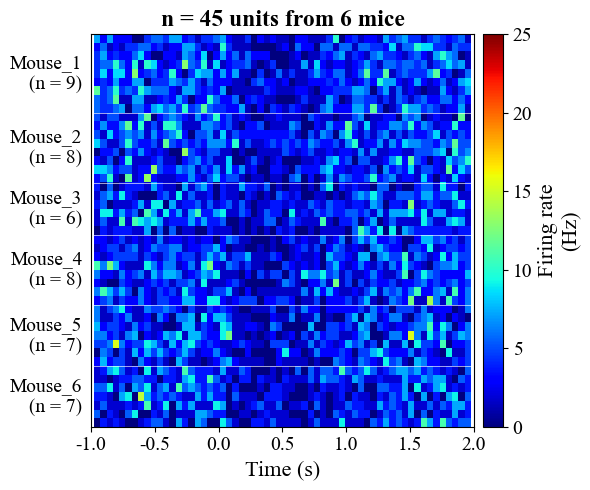

✅ Panel C Heatmap 已保存


In [17]:
# =============================================================================
# ██████████████████████████████████████████████████████████████████████████████
# 单元 5：Panel C 上图 —— 5 只小鼠 100 个神经元按小鼠分组 Heatmap
# ██████████████████████████████████████████████████████████████████████████████
# =============================================================================

# ---【参数区：可在此自定义】---
HEATMAP_C_XLIM        = (-1.0, 2.0)
HEATMAP_C_VMIN        = 0              # 颜色最小值（Hz）
HEATMAP_C_VMAX        = 25             # 颜色最大值（Hz）
HEATMAP_C_CMAP        = "jet"          # 颜色方案
HEATMAP_C_CBAR_LABEL  = "Firing rate\n(Hz)"
HEATMAP_C_TICK_X      = 0.5
HEATMAP_C_DIVIDER_COLOR = "white"      # 小鼠分组分隔线颜色
HEATMAP_C_DIVIDER_LW    = 0.45         # 分隔线线宽
HEATMAP_C_LABEL_FONTSIZE  = 16
HEATMAP_C_TICK_FONTSIZE   = 14
HEATMAP_C_TITLE_FONTSIZE  = 17
HEATMAP_C_MOUSE_LABEL_FONTSIZE = 13    # 小鼠标注字号
HEATMAP_C_FIGSIZE     = (6, 5)        # 图片尺寸
# 每只小鼠的单元数与小鼠数量由实际数据自动判断
MOUSE_LABELS = [f"{m}\n(n = {UNIT_COUNTS_BY_MOUSE.loc[m]})" for m in MOUSE_LIST]  # 侧标签

# ---【构造跨所有小鼠的矩阵（按 global_unit_index 排序）】---
df_all = df_fr.copy()
# 合并排序信息；如无 global_unit_index，则按 mouse_id + unit_id 自动排序
if "global_unit_index" in df_meta.columns:
    df_all = df_all.merge(df_meta[["unit_id", "global_unit_index"]].drop_duplicates(),
                           on="unit_id", how="left")
    df_all["unit_sort_key"] = df_all["global_unit_index"]
else:
    _unit_order = (_actual_units.assign(mouse_order=_actual_units["mouse_id"].map({m: i for i, m in enumerate(MOUSE_LIST)}))
                   .sort_values(["mouse_order", "unit_id"])
                   .reset_index(drop=True))
    _unit_order["unit_sort_key"] = np.arange(1, len(_unit_order) + 1)
    df_all = df_all.merge(_unit_order[["unit_id", "unit_sort_key"]], on="unit_id", how="left")
df_all = df_all.sort_values(["unit_sort_key", "time_bin_center_s"])

pivot_C = df_all.pivot_table(index="unit_sort_key",
                              columns="time_bin_center_s",
                              values="firing_rate_hz")
time_bins_C = pivot_C.columns.values
matrix_C    = pivot_C.values   # shape: (实际总 unit 数, n_timebins)

# ---【绘图】---
fig_C_heat, ax = plt.subplots(figsize=HEATMAP_C_FIGSIZE)

im = ax.imshow(matrix_C,
               aspect='auto',
               origin='upper',
               vmin=HEATMAP_C_VMIN,
               vmax=HEATMAP_C_VMAX,
               cmap=HEATMAP_C_CMAP,
               extent=[time_bins_C[0], time_bins_C[-1],
                       matrix_C.shape[0] + 0.5, 0.5])

# 小鼠分组分隔线：按每只小鼠实际 unit 数累计计算
_mouse_counts = UNIT_COUNTS_BY_MOUSE.loc[MOUSE_LIST].astype(int).tolist()
_mouse_boundaries = np.cumsum(_mouse_counts)[:-1]
for boundary in _mouse_boundaries:
    ax.axhline(boundary + 0.5,
               color=HEATMAP_C_DIVIDER_COLOR,
               linewidth=HEATMAP_C_DIVIDER_LW)
# 计算每组中心行号（data 坐标），作为 ytick 位置
_mouse_starts = np.r_[0, np.cumsum(_mouse_counts[:-1])]
mouse_tick_pos = [start + count / 2 + 0.5 for start, count in zip(_mouse_starts, _mouse_counts)]
ax.set_yticks(mouse_tick_pos)
ax.set_yticklabels(MOUSE_LABELS,
                   fontsize=HEATMAP_C_MOUSE_LABEL_FONTSIZE,
                   va='center')
ax.tick_params(axis='y', length=0, pad=6)   # 隐藏刻度线，只保留文字


# 色条
cbar = fig_C_heat.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(HEATMAP_C_CBAR_LABEL, fontsize=HEATMAP_C_LABEL_FONTSIZE)
cbar.ax.tick_params(labelsize=HEATMAP_C_TICK_FONTSIZE)
cbar.set_ticks([0, 5, 10, 15, 20,25])

ax.set_xlim(HEATMAP_C_XLIM)
ax.set_xlabel("Time (s)", fontsize=HEATMAP_C_LABEL_FONTSIZE)
#ax.set_ylabel("Units grouped by mouse", fontsize=HEATMAP_C_LABEL_FONTSIZE)
ax.set_title(f"n = {N_UNITS_TOTAL} units from {N_MICE} mice",
             fontsize=HEATMAP_C_TITLE_FONTSIZE, fontweight="bold")
ax.xaxis.set_major_locator(ticker.MultipleLocator(HEATMAP_C_TICK_X))
ax.tick_params(axis='both', labelsize=HEATMAP_C_TICK_FONTSIZE)


plt.tight_layout()
plt.savefig(fig_path("Panel_C_Heatmap.pdf"), dpi=300, bbox_inches='tight')
plt.show()
print("✅ Panel C Heatmap 已保存")



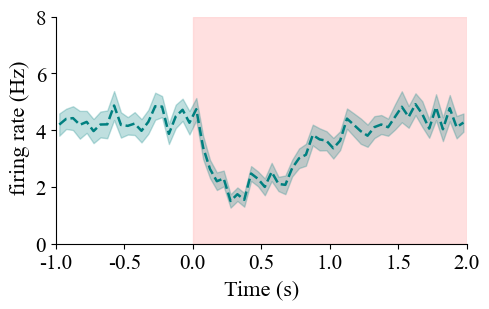

✅ Panel C PSTH 已保存


In [20]:
# =============================================================================
# ██████████████████████████████████████████████████████████████████████████████
# 单元 6：Panel C 下图 —— 5 只小鼠 Population Mean PSTH（含 SEM 阴影）
# ██████████████████████████████████████████████████████████████████████████████
# =============================================================================

# ---【参数区：可在此自定义】---
PSTH_C_XLIM         = (-1.0, 2.0)
PSTH_C_YLIM         = (0, 8)          # y 轴范围（Hz）
PSTH_C_TICK_X       = 0.5
PSTH_C_TICK_Y       = 2                # y 主刻度间距
PSTH_C_LINE_COLOR   = "#008080"        # 曲线颜色
PSTH_C_LINE_WIDTH   = 1.8
PSTH_C_LINE_STYLE   = "--"
PSTH_C_SHADE_COLOR  = "#008080"        # SEM 阴影颜色（通常与线色相同）
PSTH_C_SHADE_ALPHA  = 0.25            # SEM 阴影透明度
PSTH_C_SMOOTH_SIGMA = 0              # 平滑参数（0=不平滑）
PSTH_C_STIM_COLOR   = "#ffcccc"
PSTH_C_STIM_ALPHA   = 0.6
PSTH_C_LABEL_FONTSIZE = 16
PSTH_C_TICK_FONTSIZE  = 15

# ---【根据实际小鼠数量与 unit 数计算 Panel C population mean PSTH + SEM】---
# 先得到每个 unit 在每个 time bin 的 firing rate，再跨 unit 计算 mean/SEM。
df_unit_time_C = (df_fr.groupby(["unit_id", "time_bin_center_s"], as_index=False)["firing_rate_hz"]
                  .mean())
df_summary_C_actual = (df_unit_time_C.groupby("time_bin_center_s")["firing_rate_hz"]
                       .agg(mean_firing_rate_hz="mean", sem_hz="sem")
                       .reset_index()
                       .sort_values("time_bin_center_s"))

t_C   = df_summary_C_actual["time_bin_center_s"].values
fr_C  = df_summary_C_actual["mean_firing_rate_hz"].values
sem_C = df_summary_C_actual["sem_hz"].fillna(0).values

if PSTH_C_SMOOTH_SIGMA > 0:
    fr_C  = gaussian_filter1d(fr_C,  sigma=PSTH_C_SMOOTH_SIGMA)
    sem_C = gaussian_filter1d(sem_C, sigma=PSTH_C_SMOOTH_SIGMA)

# ---【绘图】---
fig_C_psth, ax = plt.subplots(figsize=(5, 3.2))

ax.axvspan(STIM_ONSET, STIM_OFFSET,
           color=PSTH_C_STIM_COLOR, alpha=PSTH_C_STIM_ALPHA, zorder=0)

# SEM 阴影
ax.fill_between(t_C,
                fr_C - sem_C,
                fr_C + sem_C,
                color=PSTH_C_SHADE_COLOR,
                alpha=PSTH_C_SHADE_ALPHA)

# 均值曲线
ax.plot(t_C, fr_C,
        color=PSTH_C_LINE_COLOR,
        linewidth=PSTH_C_LINE_WIDTH,
        linestyle=PSTH_C_LINE_STYLE)

# 刺激箭头标注
# 依据 PSTH_C_YLIM 动态计算箭头与文字的 y 位置，随 y 轴范围等比缩放
y_min, y_max = PSTH_C_YLIM
y_range = y_max - y_min  # y 轴总跨度
arrow_tip_y = y_min - y_range * 0.10  # 箭头尖端：y 轴下方 5%
arrow_text_y = y_min - y_range * 0.2  # 文字位置：y 轴下方 18%

#ax.annotate("stimulus onset",
 #           xy=(STIM_ONSET, arrow_tip_y),  # 箭头尖端位置（随 ylim 缩放）
    #        xytext=(STIM_ONSET, arrow_text_y),  # 文字位置（随 ylim 缩放）
     #       fontsize=9,
      #      ha='center',
      #      arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
       #     annotation_clip=False)

ax.set_xlim(PSTH_C_XLIM)
ax.set_ylim(PSTH_C_YLIM)
ax.set_xlabel("Time (s)",                      fontsize=PSTH_C_LABEL_FONTSIZE)
ax.set_ylabel(" firing rate (Hz)", fontsize=PSTH_C_LABEL_FONTSIZE)
ax.xaxis.set_major_locator(ticker.MultipleLocator(PSTH_C_TICK_X))
ax.yaxis.set_major_locator(ticker.MultipleLocator(PSTH_C_TICK_Y))
ax.tick_params(axis='both', labelsize=PSTH_C_TICK_FONTSIZE)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path("Panel_C_PSTH.pdf"), dpi=300, bbox_inches='tight')
plt.show()
print("✅ Panel C PSTH 已保存")

Z-score重做分析

In [21]:
# =============================================================================
# 单元 Z1：对每个神经元按刺激前基线做 z-score
# =============================================================================

import numpy as np
import pandas as pd

ZSCORE_BASELINE_WINDOW = (-1.0, 0.0)  # 用刺激前 -1~0 s 作为 baseline

df_fr_z = df_fr.copy()

baseline_stats = (
    df_fr_z[
        (df_fr_z["time_bin_center_s"] >= ZSCORE_BASELINE_WINDOW[0]) &
        (df_fr_z["time_bin_center_s"] < ZSCORE_BASELINE_WINDOW[1])
        ]
    .groupby(["mouse_id", "unit_id"])["firing_rate_hz"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "baseline_mean_hz",
        "std": "baseline_std_hz"
    })
)

# 避免 std=0 导致除零
baseline_stats["baseline_std_hz"] = baseline_stats["baseline_std_hz"].replace(0, np.nan)

df_fr_z = df_fr_z.merge(
    baseline_stats,
    on=["mouse_id", "unit_id"],
    how="left"
)

df_fr_z["firing_rate_zscore"] = (
                                        df_fr_z["firing_rate_hz"] - df_fr_z["baseline_mean_hz"]
                                ) / df_fr_z["baseline_std_hz"]

df_fr_z["firing_rate_zscore"] = df_fr_z["firing_rate_zscore"].fillna(0)

print("✅ z-score 数据已生成：df_fr_z")
print(df_fr_z.head())


✅ z-score 数据已生成：df_fr_z
  mouse_id  unit_id  time_bin_center_s  time_bin_start_s  time_bin_end_s  \
0  Mouse_1  M1_U001             -0.975             -1.00           -0.95   
1  Mouse_1  M1_U001             -0.925             -0.95           -0.90   
2  Mouse_1  M1_U001             -0.875             -0.90           -0.85   
3  Mouse_1  M1_U001             -0.825             -0.85           -0.80   
4  Mouse_1  M1_U001             -0.775             -0.80           -0.75   

   spike_count  firing_rate_hz  n_trials  is_stimulus_period  \
0            5          7.1429        14               False   
1            2          2.8571        14               False   
2            5          7.1429        14               False   
3            2          2.8571        14               False   
4            2          2.8571        14               False   

   baseline_mean_hz  baseline_std_hz  firing_rate_zscore  
0          4.142855            2.218            1.352590  
1          4.142

In [22]:
# =============================================================================
# 单元 Z2：生成 z-score summary 数据
# =============================================================================

summary_z_rows = []

for tc in sorted(df_fr_z["time_bin_center_s"].unique()):

    # Panel A：当前选择的单个 unit
    a = df_fr_z[
        (df_fr_z["mouse_id"] == DEFAULT_MOUSE_ID) &
        (df_fr_z["unit_id"] == DEFAULT_UNIT_ID) &
        (df_fr_z["time_bin_center_s"] == tc)
        ]["firing_rate_zscore"]

    if len(a):
        summary_z_rows.append({
            "summary": "Panel_A_single_unit_zscore",
            "mouse_id": DEFAULT_MOUSE_ID,
            "unit_id": DEFAULT_UNIT_ID,
            "time_bin_center_s": tc,
            "mean_zscore": float(a.mean()),
            "sem_zscore": ""
        })

    # Panel B：当前小鼠所有 unit 平均
    b = df_fr_z[
        (df_fr_z["mouse_id"] == DEFAULT_MOUSE_ID) &
        (df_fr_z["time_bin_center_s"] == tc)
        ]["firing_rate_zscore"]

    if len(b):
        summary_z_rows.append({
            "summary": "Panel_B_single_mouse_multi_unit_zscore",
            "mouse_id": DEFAULT_MOUSE_ID,
            "unit_id": "all_units",
            "time_bin_center_s": tc,
            "mean_zscore": float(b.mean()),
            "sem_zscore": float(b.sem()) if len(b) > 1 else 0
        })

    # ──────────────────────────────────────────────────────────────
    # 【新增】Panel B_all：每只小鼠各自所有 unit 的 z-score 平均
    #         （供单元 Z4 遍历所有小鼠时使用）
    # ──────────────────────────────────────────────────────────────
    for _mid in MOUSE_LIST:
        b_all = df_fr_z[
            (df_fr_z["mouse_id"] == _mid) &
            (df_fr_z["time_bin_center_s"] == tc)
        ]["firing_rate_zscore"]
        if len(b_all):
            summary_z_rows.append({
                "summary": "Panel_B_per_mouse_zscore",
                "mouse_id": _mid,
                "unit_id": "all_units",
                "time_bin_center_s": tc,
                "mean_zscore": float(b_all.mean()),
                "sem_zscore": float(b_all.sem()) if len(b_all) > 1 else 0
            })

    # Panel C：所有小鼠所有 unit 平均
    c = df_fr_z[
        df_fr_z["time_bin_center_s"] == tc
        ]["firing_rate_zscore"]

    if len(c):
        summary_z_rows.append({
            "summary": "Panel_C_population_zscore",
            "mouse_id": "all_mice",
            "unit_id": "all_units",
            "time_bin_center_s": tc,
            "mean_zscore": float(c.mean()),
            "sem_zscore": float(c.sem()) if len(c) > 1 else 0
        })

df_summary_z = pd.DataFrame(summary_z_rows)

print("✅ z-score summary 已生成：df_summary_z")
print(df_summary_z.head())


✅ z-score summary 已生成：df_summary_z
                                  summary mouse_id    unit_id  \
0              Panel_A_single_unit_zscore  Mouse_4    M4_U001   
1  Panel_B_single_mouse_multi_unit_zscore  Mouse_4  all_units   
2                Panel_B_per_mouse_zscore  Mouse_1  all_units   
3                Panel_B_per_mouse_zscore  Mouse_2  all_units   
4                Panel_B_per_mouse_zscore  Mouse_3  all_units   

   time_bin_center_s  mean_zscore sem_zscore  
0             -0.975     0.347007             
1             -0.975     0.017695   0.310859  
2             -0.975     0.231810   0.325659  
3             -0.975     0.072815     0.2885  
4             -0.975    -0.640238   0.243604  


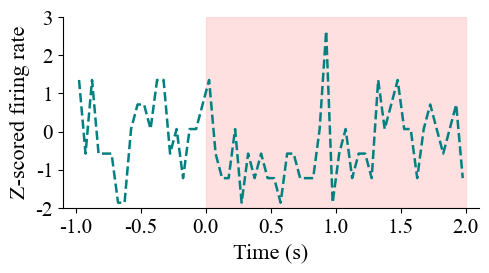

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U001.pdf


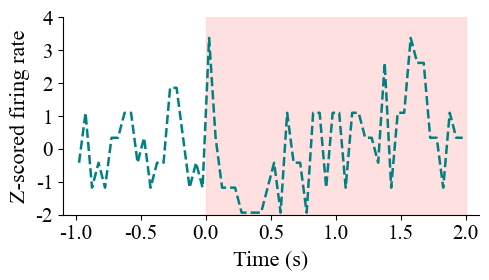

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U002.pdf


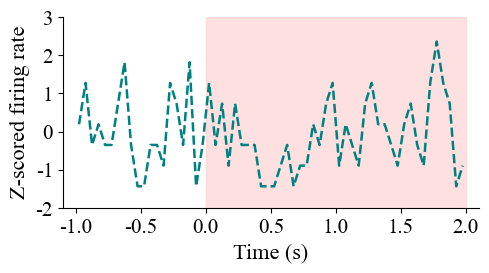

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U003.pdf


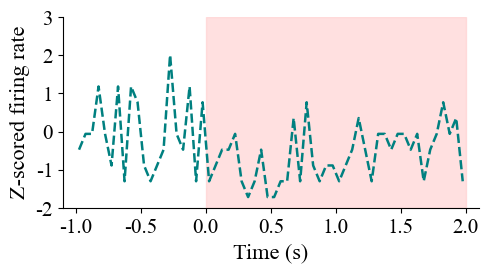

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U004.pdf


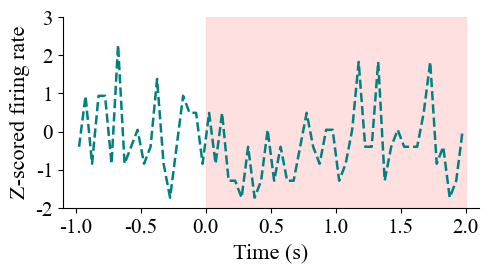

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U005.pdf


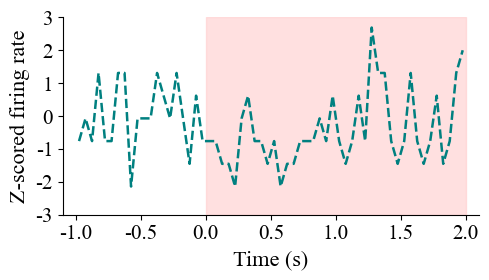

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U006.pdf


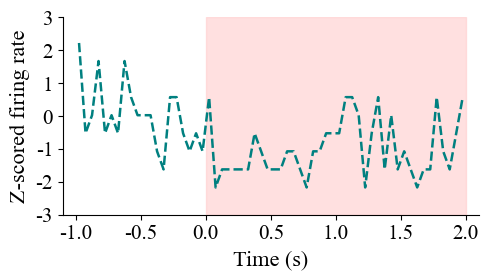

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U007.pdf


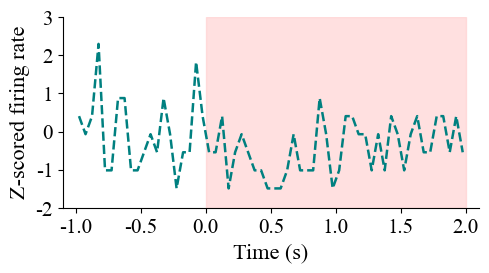

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U008.pdf


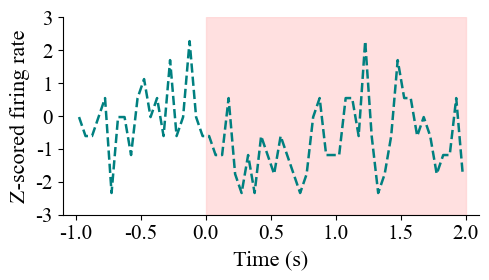

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_1_M1_U009.pdf


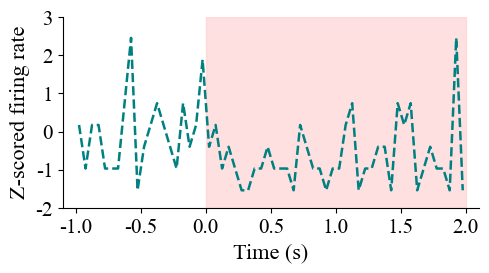

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U001.pdf


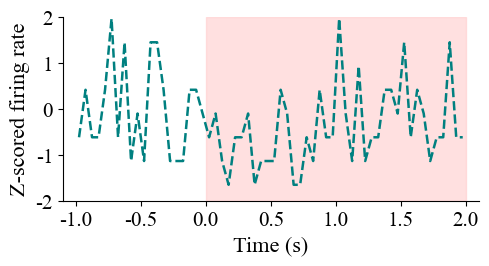

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U002.pdf


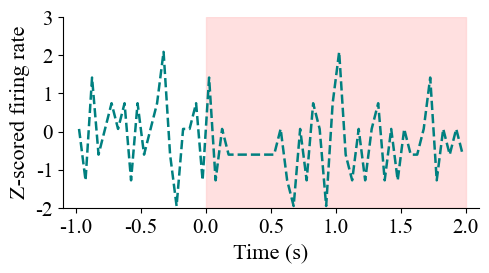

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U003.pdf


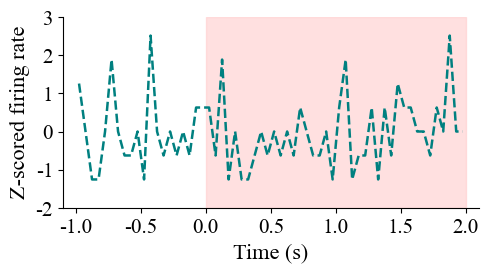

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U004.pdf


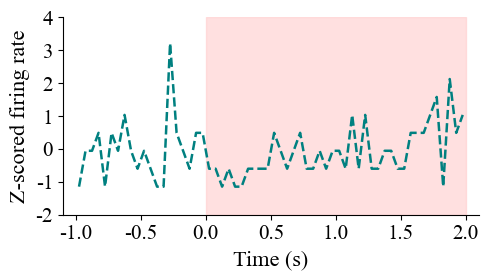

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U005.pdf


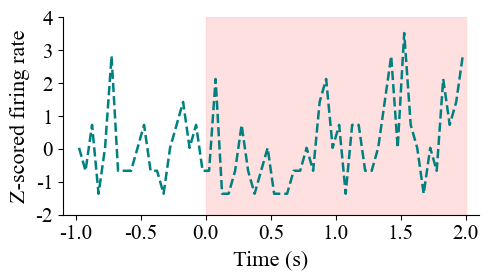

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U006.pdf


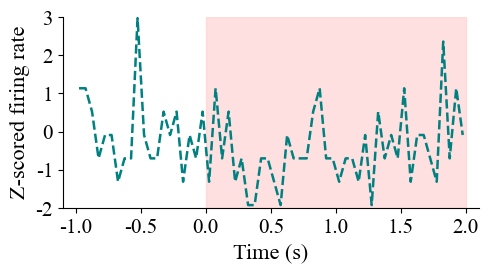

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U007.pdf


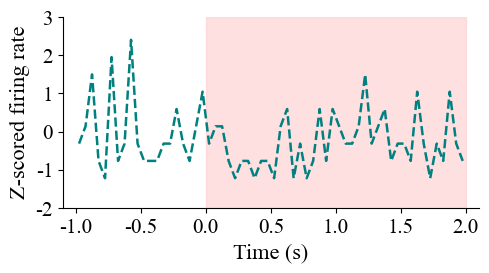

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_2_M2_U008.pdf


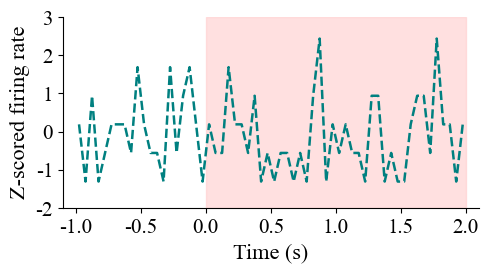

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_3_M3_U001.pdf


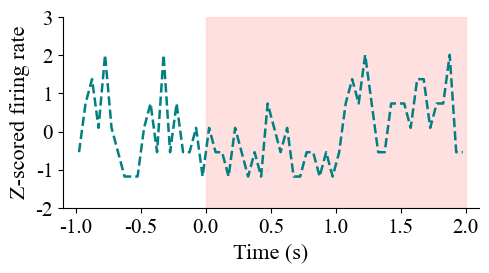

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_3_M3_U002.pdf


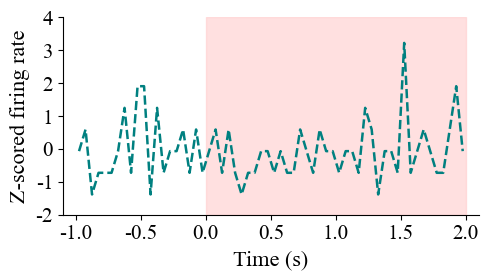

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_3_M3_U003.pdf


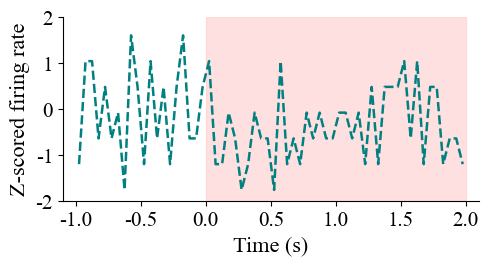

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_3_M3_U004.pdf


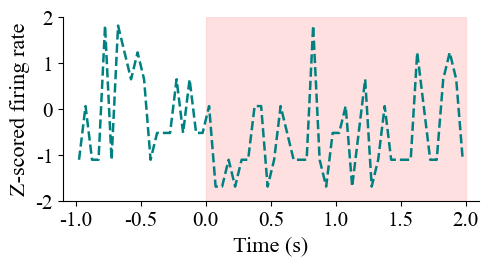

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_3_M3_U005.pdf


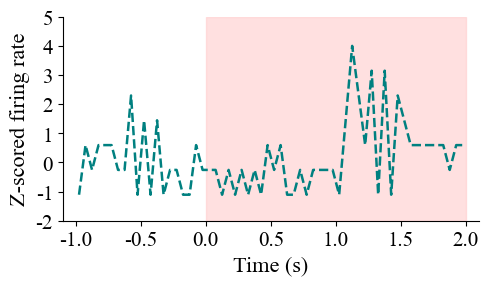

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_3_M3_U006.pdf


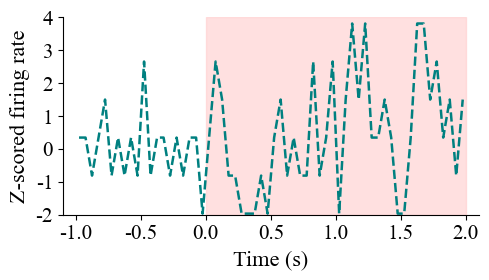

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U001.pdf


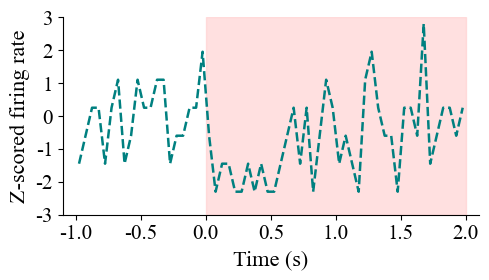

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U002.pdf


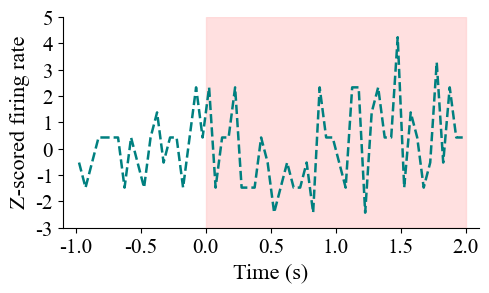

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U003.pdf


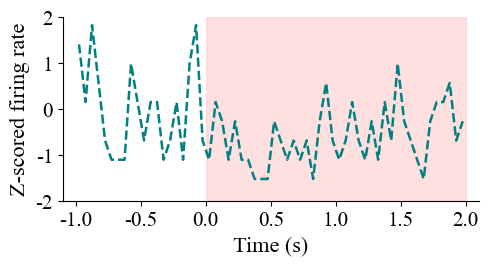

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U004.pdf


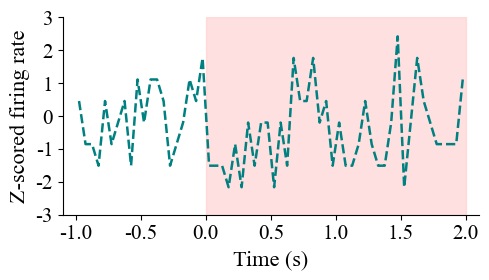

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U005.pdf


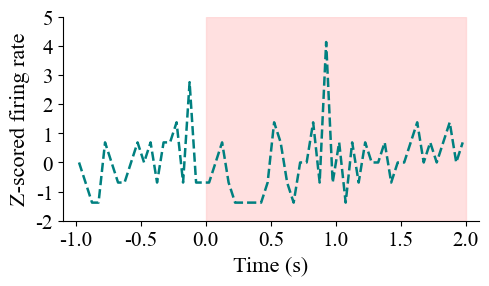

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U006.pdf


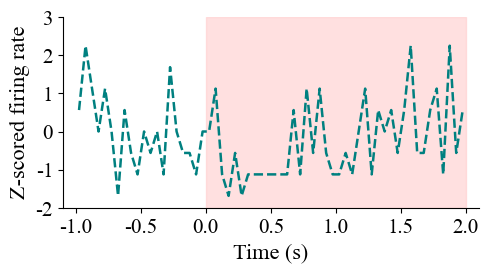

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U007.pdf


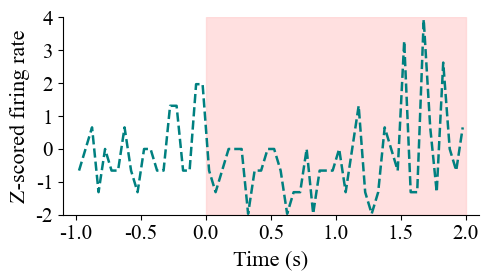

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_4_M4_U008.pdf


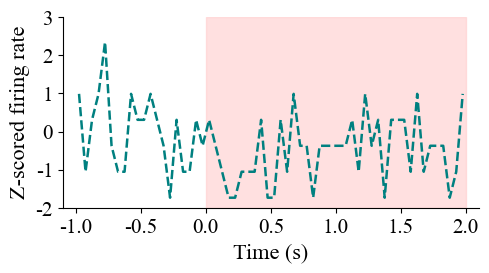

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U001.pdf


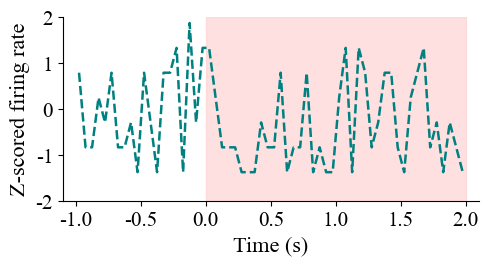

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U002.pdf


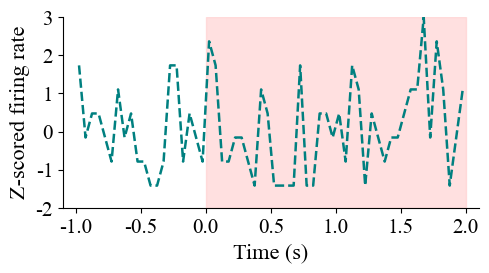

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U003.pdf


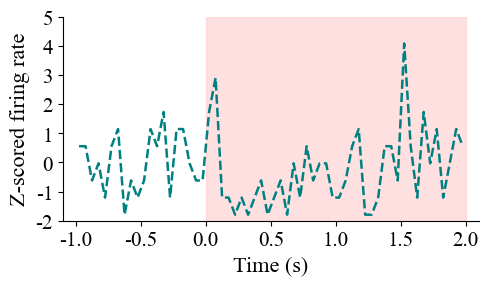

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U004.pdf


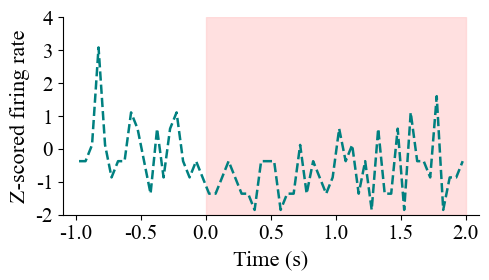

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U005.pdf


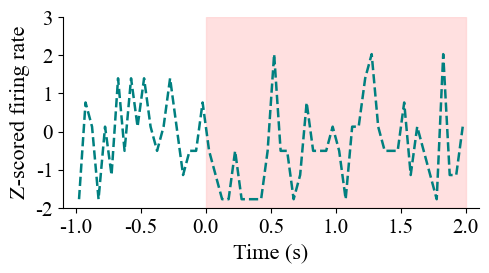

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U006.pdf


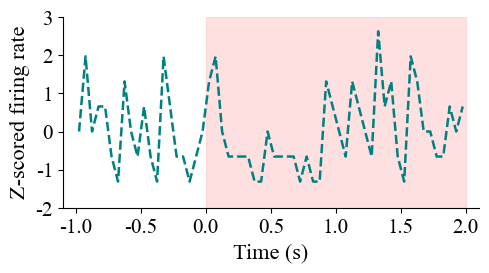

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_5_M5_U007.pdf


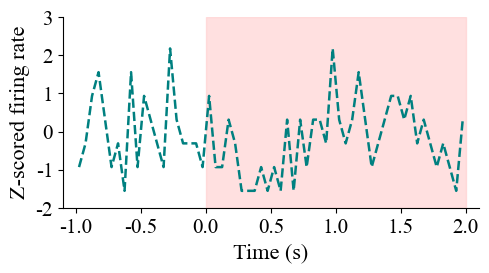

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U001.pdf


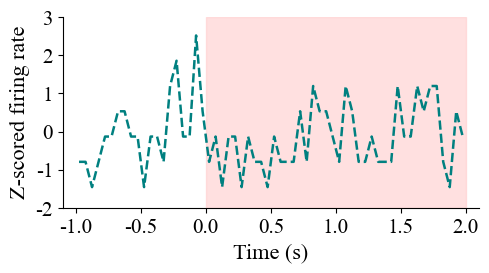

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U002.pdf


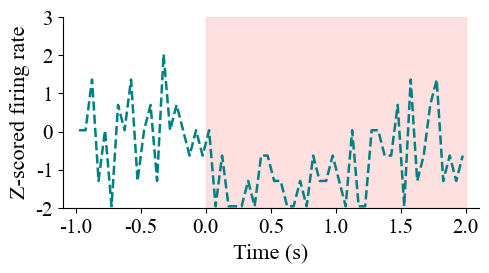

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U003.pdf


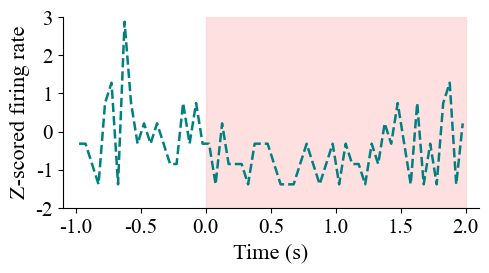

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U004.pdf


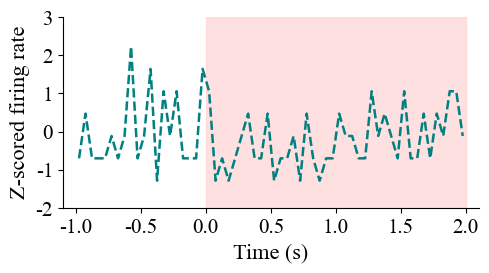

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U005.pdf


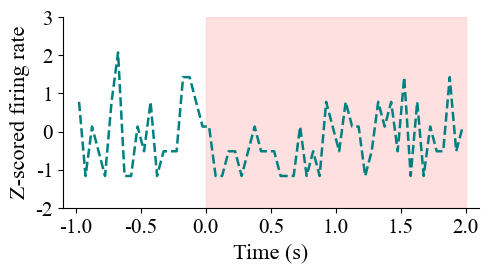

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U006.pdf


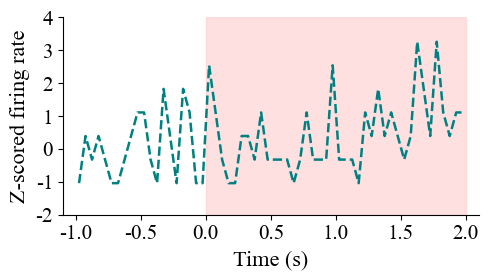

✅ Panel A z-score PSTH 已保存：Panel_A_Zscore_PSTH_Mouse_6_M6_U007.pdf


In [23]:
# =============================================================================
# 单元 Z3：Panel A —— 所有小鼠、所有单个神经元 z-score PSTH
#          图片高度随 z-score 数据范围自动调整
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.ndimage import gaussian_filter1d

# ---【参数区】---
Z_A_XLIM        = (-1.1, 2.1)
Z_A_YLIM_MIN    = (-2, 2)      # 默认 y 轴范围（数据超出则自动扩展）
Z_A_TICK_X      = 0.5
Z_A_TICK_Y      = 1

Z_A_LINE_COLOR  = "#008080"
Z_A_LINE_WIDTH  = 1.8
Z_A_LINE_STYLE  = "--"
Z_A_SMOOTH_SIGMA = 0

Z_A_STIM_COLOR  = "#ffcccc"
Z_A_STIM_ALPHA  = 0.6

# ---【遍历所有小鼠和所有单元】---
for _mouse_id in MOUSE_LIST:
    _units = sorted(
        _actual_units[_actual_units["mouse_id"] == _mouse_id]["unit_id"].unique()
    )
    for _unit_id in _units:
        df_A_z = df_fr_z[
            (df_fr_z["mouse_id"] == _mouse_id) &
            (df_fr_z["unit_id"]  == _unit_id)
        ].sort_values("time_bin_center_s")

        t_A_z = df_A_z["time_bin_center_s"].values
        z_A   = df_A_z["firing_rate_zscore"].values

        if Z_A_SMOOTH_SIGMA > 0:
            z_A = gaussian_filter1d(z_A, sigma=Z_A_SMOOTH_SIGMA)

        # ---【y 轴范围随数据自动调整】---
        _z_min = z_A.min() if len(z_A) > 0 else Z_A_YLIM_MIN[0]
        _z_max = z_A.max() if len(z_A) > 0 else Z_A_YLIM_MIN[1]
        _ylim_lo  = min(Z_A_YLIM_MIN[0], float(np.floor(_z_min)))
        _ylim_hi  = max(Z_A_YLIM_MIN[1], float(np.ceil( _z_max)))
        _ylim     = (_ylim_lo, _ylim_hi)
        # 图片高度与 y 轴总跨度成比例
        _y_range  = _ylim_hi - _ylim_lo
        fig_h     = max(2.5, 2.5 + _y_range / 6 * 0.4)

        fig, ax = plt.subplots(figsize=(5, fig_h))

        ax.axvspan(STIM_ONSET, STIM_OFFSET,
                   color=Z_A_STIM_COLOR, alpha=Z_A_STIM_ALPHA, zorder=0)

        ax.plot(t_A_z, z_A,
                color=Z_A_LINE_COLOR,
                linewidth=Z_A_LINE_WIDTH,
                linestyle=Z_A_LINE_STYLE)

        ax.set_xlim(Z_A_XLIM)
        ax.set_ylim(_ylim)
        ax.set_xlabel("Time (s)", fontsize=16)
        ax.set_ylabel("Z-scored firing rate", fontsize=16)
        #ax.set_title(
        #    f"PSTH (Peri-Stimulus Time Histogram)",
         #   fontsize=12, fontweight="bold"
        #)

        ax.xaxis.set_major_locator(ticker.MultipleLocator(Z_A_TICK_X))
        ax.yaxis.set_major_locator(ticker.MultipleLocator(Z_A_TICK_Y))
        ax.tick_params(axis="both", labelsize=15)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        plt.tight_layout()
        _fname = f"Panel_A_Zscore_PSTH_{_mouse_id}_{_unit_id}.pdf"
        plt.savefig(fig_path(_fname), dpi=300, bbox_inches="tight")
        plt.show()
        print(f"✅ Panel A z-score PSTH 已保存：{_fname}")


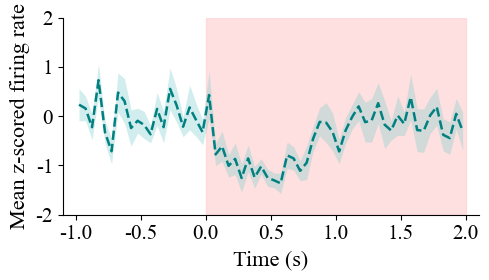

✅ Panel B z-score mean PSTH 已保存：Panel_B_Zscore_Mean_PSTH_Mouse_1.pdf


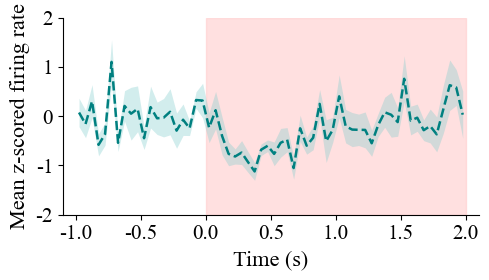

✅ Panel B z-score mean PSTH 已保存：Panel_B_Zscore_Mean_PSTH_Mouse_2.pdf


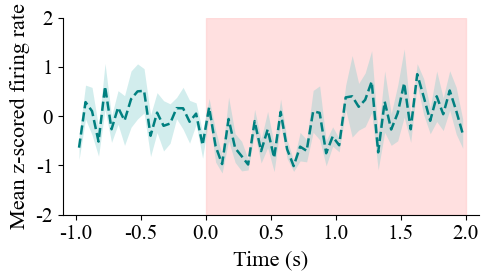

✅ Panel B z-score mean PSTH 已保存：Panel_B_Zscore_Mean_PSTH_Mouse_3.pdf


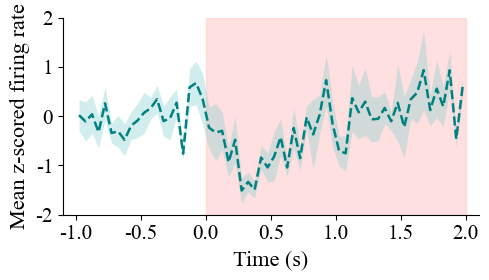

✅ Panel B z-score mean PSTH 已保存：Panel_B_Zscore_Mean_PSTH_Mouse_4.pdf


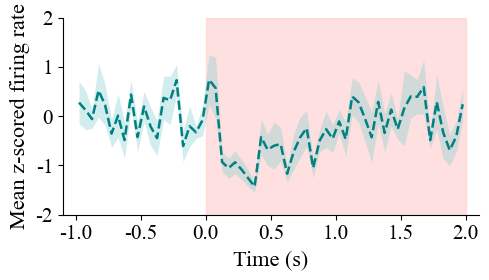

✅ Panel B z-score mean PSTH 已保存：Panel_B_Zscore_Mean_PSTH_Mouse_5.pdf


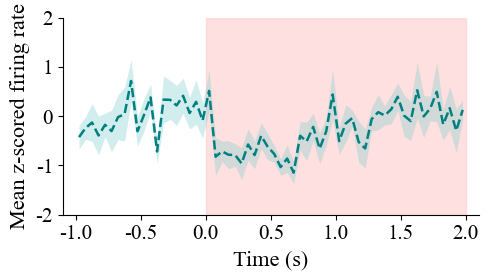

✅ Panel B z-score mean PSTH 已保存：Panel_B_Zscore_Mean_PSTH_Mouse_6.pdf


In [24]:
# =============================================================================
# 单元 Z4：Panel B —— 所有小鼠各自所有 unit 的 z-score 平均 PSTH
#          图片高度随 z-score 数据范围自动调整
# =============================================================================

# ---【参数区】---
Z_B_XLIM        = (-1.1, 2.1)
Z_B_YLIM_MIN    = (-2, 2)      # 默认 y 轴范围（数据超出则自动扩展）
Z_B_TICK_X      = 0.5
Z_B_TICK_Y      = 1

Z_B_LINE_COLOR  = "#008080"
Z_B_SEM_COLOR   = "#80cccc"
Z_B_LINE_WIDTH  = 1.8
Z_B_LINE_STYLE  = "--"
Z_B_SEM_ALPHA   = 0.35
Z_B_SMOOTH_SIGMA = 0

Z_B_STIM_COLOR  = "#ffcccc"
Z_B_STIM_ALPHA  = 0.6

# ---【遍历所有小鼠】---
for _mouse_id in MOUSE_LIST:
    df_B_z = df_summary_z[
        (df_summary_z["summary"]  == "Panel_B_per_mouse_zscore") &
        (df_summary_z["mouse_id"] == _mouse_id)
    ].sort_values("time_bin_center_s")

    t_B_z    = df_B_z["time_bin_center_s"].values
    mean_B_z = df_B_z["mean_zscore"].values
    sem_B_z  = pd.to_numeric(df_B_z["sem_zscore"]).values

    if Z_B_SMOOTH_SIGMA > 0:
        mean_B_z = gaussian_filter1d(mean_B_z, sigma=Z_B_SMOOTH_SIGMA)
        sem_B_z  = gaussian_filter1d(sem_B_z,  sigma=Z_B_SMOOTH_SIGMA)

    # ---【y 轴范围随数据自动调整】---
    if len(mean_B_z) > 0:
        _z_lo = (mean_B_z - sem_B_z).min()
        _z_hi = (mean_B_z + sem_B_z).max()
    else:
        _z_lo, _z_hi = Z_B_YLIM_MIN
    _ylim_lo  = min(Z_B_YLIM_MIN[0], float(np.floor(_z_lo)))
    _ylim_hi  = max(Z_B_YLIM_MIN[1], float(np.ceil( _z_hi)))
    _ylim     = (_ylim_lo, _ylim_hi)
    # 图片高度与 y 轴总跨度成比例
    _y_range  = _ylim_hi - _ylim_lo
    fig_h     = max(2.5, 2.5 + _y_range / 4 * 0.4)

    fig, ax = plt.subplots(figsize=(5, fig_h))

    ax.axvspan(STIM_ONSET, STIM_OFFSET,
               color=Z_B_STIM_COLOR, alpha=Z_B_STIM_ALPHA, zorder=0)

    ax.fill_between(
        t_B_z,
        mean_B_z - sem_B_z,
        mean_B_z + sem_B_z,
        color=Z_B_SEM_COLOR,
        alpha=Z_B_SEM_ALPHA,
        linewidth=0
    )

    ax.plot(t_B_z, mean_B_z,
            color=Z_B_LINE_COLOR,
            linewidth=Z_B_LINE_WIDTH,
            linestyle=Z_B_LINE_STYLE)

    ax.set_xlim(Z_B_XLIM)
    ax.set_ylim(_ylim)
    ax.set_xlabel("Time (s)", fontsize=16)
    ax.set_ylabel("Mean z-scored firing rate", fontsize=16)
    #ax.set_title(
      #  f"PSTH (Peri-Stimulus Time Histogram)",
        #fontsize=12, fontweight="bold"
    #)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(Z_B_TICK_X))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(Z_B_TICK_Y))
    ax.tick_params(axis="both", labelsize=15)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    _fname = f"Panel_B_Zscore_Mean_PSTH_{_mouse_id}.pdf"
    plt.savefig(fig_path(_fname), dpi=300, bbox_inches="tight")
    plt.show()
    print(f"✅ Panel B z-score mean PSTH 已保存：{_fname}")


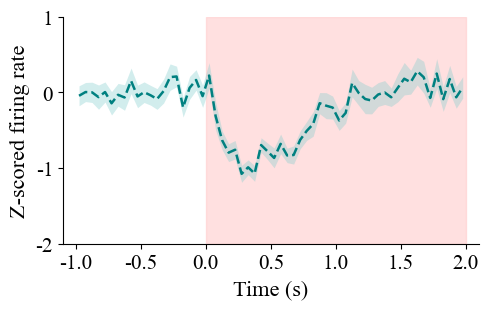

✅ Panel C z-score population PSTH 已保存


In [25]:
# =============================================================================
# 单元 Z5：Panel C —— 所有小鼠所有 unit 的 z-score 群体平均 PSTH
# =============================================================================

# ---【参数区】---
Z_C_XLIM = (-1.1, 2.1)
Z_C_YLIM = (-2, 1)
Z_C_TICK_X = 0.5
Z_C_TICK_Y = 1

Z_C_LINE_COLOR = "#008080"
Z_C_SEM_COLOR = "#80cccc"
Z_C_LINE_WIDTH = 1.8
Z_C_LINE_STYLE = "--"
Z_C_SEM_ALPHA = 0.35

df_C_z = df_summary_z[
    df_summary_z["summary"] == "Panel_C_population_zscore"
    ].sort_values("time_bin_center_s")

t_C_z = df_C_z["time_bin_center_s"].values
mean_C_z = df_C_z["mean_zscore"].values
sem_C_z = pd.to_numeric(df_C_z["sem_zscore"]).values

fig, ax = plt.subplots(figsize=(5, 3.2))

ax.axvspan(
    STIM_ONSET,
    STIM_OFFSET,
    color="#ffcccc",
    alpha=0.6,
    zorder=0
)

ax.fill_between(
    t_C_z,
    mean_C_z - sem_C_z,
    mean_C_z + sem_C_z,
    color=Z_C_SEM_COLOR,
    alpha=Z_C_SEM_ALPHA,
    linewidth=0
)

ax.plot(
    t_C_z,
    mean_C_z,
    color=Z_C_LINE_COLOR,
    linewidth=Z_C_LINE_WIDTH,
    linestyle=Z_C_LINE_STYLE
)

#ax.axhline(0, color="black", linewidth=0.8)

ax.set_xlim(Z_C_XLIM)
ax.set_ylim(Z_C_YLIM)
ax.set_xlabel("Time (s)", fontsize=16)
ax.set_ylabel("Z-scored firing rate", fontsize=16)
#ax.set_title(
 #   "PSTH (Peri-Stimulus Time Histogram)",
   # fontsize=12,
   # fontweight="bold"
#)

ax.xaxis.set_major_locator(ticker.MultipleLocator(Z_C_TICK_X))
ax.yaxis.set_major_locator(ticker.MultipleLocator(Z_C_TICK_Y))
ax.tick_params(axis="both", labelsize=15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path("Panel_C_Zscore_Population_PSTH.pdf"), dpi=300, bbox_inches="tight")
plt.show()

print("✅ Panel C z-score population PSTH 已保存")


In [26]:
# =============================================================================
# 单元 Z6：保存 z-score 数据
# =============================================================================

df_fr_z.to_csv(fig_path("zscore_psth_binned_firing_rates.csv"), index=False)
df_summary_z.to_csv(fig_path("zscore_summary_psth_curves.csv"), index=False)

print("✅ z-score 数据已保存")
print(fig_path("zscore_psth_binned_firing_rates.csv"))
print(fig_path("zscore_summary_psth_curves.csv"))


✅ z-score 数据已保存
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\psth_In_sd_data_csv3-5\zscore_psth_binned_firing_rates.csv
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\psth_In_sd_data_csv3-5\zscore_summary_psth_curves.csv


统计分析

In [32]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_rel, shapiro

# 设置文件路径
file_path = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\psth_In_sd_data_csv3-5\psth_binned_firing_rates.csv"

df = pd.read_csv(file_path)

# 定义刺激前后窗口
baseline_df = df[(df["time_bin_center_s"] >= -1) & (df["time_bin_center_s"] < 0)]
stimulus_df = df[(df["time_bin_center_s"] >= 0) & (df["time_bin_center_s"] <= 2)]

# 每个神经元刺激前平均放电率
baseline_unit = (
    baseline_df
    .groupby(["mouse_id", "unit_id"])["firing_rate_hz"]
    .mean()
    .reset_index(name="baseline_hz")
)

# 每个神经元刺激后平均放电率
stimulus_unit = (
    stimulus_df
    .groupby(["mouse_id", "unit_id"])["firing_rate_hz"]
    .mean()
    .reset_index(name="stimulus_hz")
)

# 合并，保证同一个神经元前后配对
unit_stats = pd.merge(
    baseline_unit,
    stimulus_unit,
    on=["mouse_id", "unit_id"]
)

unit_stats["delta_hz"] = unit_stats["stimulus_hz"] - unit_stats["baseline_hz"]

# 所有小鼠的所有神经元一起做 paired t-test
t_stat, p_value = ttest_rel(
    unit_stats["stimulus_hz"],
    unit_stats["baseline_hz"]
)

# 正态性检验：检验每个神经元 paired difference
shapiro_stat, shapiro_p = shapiro(unit_stats["delta_hz"])

print(unit_stats)

print("Number of units:", len(unit_stats))
print("Baseline:", unit_stats["baseline_hz"].mean(), "±", unit_stats["baseline_hz"].sem(), "Hz")
print("Stimulus:", unit_stats["stimulus_hz"].mean(), "±", unit_stats["stimulus_hz"].sem(), "Hz")
print("Delta:", unit_stats["delta_hz"].mean(), "±", unit_stats["delta_hz"].sem(), "Hz")

print("2-tailed uppaired Student's t-test")
print("t =", t_stat)
print("p =", p_value)

print("Shapiro-Wilk test on paired differences")
print("W =", shapiro_stat)
print("p =", shapiro_p)


   mouse_id  unit_id  baseline_hz  stimulus_hz  delta_hz
0   Mouse_1  M1_U001     4.142855     3.250000 -0.892855
1   Mouse_1  M1_U002     3.642855     3.892858  0.250003
2   Mouse_1  M1_U003     3.785700     3.500002 -0.285697
3   Mouse_1  M1_U004     5.928565     3.714290 -2.214275
4   Mouse_1  M1_U005     5.571410     4.214292 -1.357118
5   Mouse_1  M1_U006     4.428570     3.499992 -0.928577
6   Mouse_1  M1_U007     5.642860     3.035722 -2.607138
7   Mouse_1  M1_U008     4.500005     3.107143 -1.392862
8   Mouse_1  M1_U009     5.785720     3.892858 -1.892862
9   Mouse_2  M2_U001     4.500010     2.541678 -1.958333
10  Mouse_2  M2_U002     5.333345     4.000000 -1.333345
11  Mouse_2  M2_U003     4.833340     3.958330 -0.875010
12  Mouse_2  M2_U004     5.000000     4.875002 -0.124998
13  Mouse_2  M2_U005     3.499995     3.166677 -0.333318
14  Mouse_2  M2_U006     3.250005     3.666670  0.416665
15  Mouse_2  M2_U007     5.249995     3.916660 -1.333335
16  Mouse_2  M2_U008     4.5000

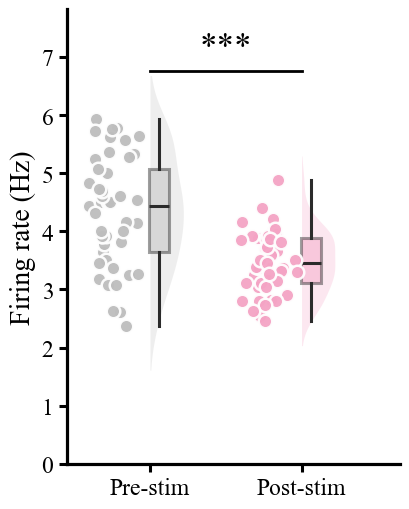

In [33]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# =========================
# 半散点 + 半阴影箱线图
# Pre-stim vs Post-stim
# =========================

# 提取数据
pre_data = unit_stats["baseline_hz"].values
post_data = unit_stats["stimulus_hz"].values

# 颜色
pre_color = "#BDBDBD"
post_color = "#F4A3C4"
box_edge_color = "#2B2B2B"

# x 轴位置
x_positions = [1, 2]
labels = ["Pre-stim", "Post-stim"]
data_list = [pre_data, post_data]
color_list = [pre_color, post_color]

plt.figure(figsize=(4.2, 5.2))

ax = plt.gca()

# 控制图形宽度
scatter_width = 0.10      # 散点抖动范围
violin_width = 0.22       # 半小提琴宽度
box_width = 0.13          # 箱线图宽度
gap = 0.03                # 散点和箱线图之间的间隔

np.random.seed(1)

for x, data, color in zip(x_positions, data_list, color_list):

    # -------------------------
    # 左半边散点
    # -------------------------
    jitter = np.random.normal(
        loc=x - violin_width - gap,
        scale=scatter_width,
        size=len(data)
    )

    # 限制散点不要跑到右侧
    jitter = np.clip(
        jitter,
        x - violin_width - 0.18,
        x - gap
    )

    ax.scatter(
        jitter,
        data,
        s=95,
        color=color,
        edgecolor="white",
        linewidth=1.8,
        alpha=0.95,
        zorder=4
    )

    # -------------------------
    # 右半边阴影，小提琴图
    # -------------------------
    y_min = max(0, data.min() - data.std() * 0.8)
    y_max = data.max() + data.std() * 0.8

    y_grid = np.linspace(y_min, y_max, 300)

    if len(np.unique(data)) > 1:
        kde = gaussian_kde(data)
        density = kde(y_grid)
        density = density / density.max() * violin_width
    else:
        density = np.ones_like(y_grid) * violin_width * 0.3

    ax.fill_betweenx(
        y_grid,
        x,
        x + density,
        color=color,
        alpha=0.25,
        linewidth=0,
        zorder=1
    )

    # -------------------------
    # 右半边箱线图
    # -------------------------
    box = ax.boxplot(
        data,
        positions=[x + violin_width * 0.28],
        widths=box_width,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color=box_edge_color, linewidth=2.2),
        boxprops=dict(
            facecolor=color,
            alpha=0.45,
            color=box_edge_color,
            linewidth=2.2
        ),
        whiskerprops=dict(color=box_edge_color, linewidth=2.2),
        capprops=dict(color=box_edge_color, linewidth=0)
    )

    # 去掉上下 cap，更接近示例图
    for cap in box["caps"]:
        cap.set_visible(False)

# -------------------------
# 显著性标记
# -------------------------
y_top = max(pre_data.max(), post_data.max())
y_sig = y_top * 1.14
line_y = y_sig
text_y = y_sig * 1.02

ax.plot(
    [x_positions[0], x_positions[1]],
    [line_y, line_y],
    color="black",
    linewidth=2
)

if p_value < 0.001:
    sig_text = "***"
elif p_value < 0.01:
    sig_text = "**"
elif p_value < 0.05:
    sig_text = "*"
else:
    sig_text = "ns"

ax.text(
    np.mean(x_positions),
    text_y,
    sig_text,
    ha="center",
    va="bottom",
    fontsize=25,
    fontweight="regular"
)

# -------------------------
# 坐标轴设置
# -------------------------
ax.set_xticks(x_positions)
ax.set_xticklabels(
    labels,
    fontsize=19,
    fontweight="regular"
)

ax.set_ylabel(
    "Firing rate (Hz)",
    fontsize=20,
    fontweight="regular"
)

# y 轴范围
y_max_plot = y_top * 1.32
ax.set_ylim(0, y_max_plot)

# x 轴范围，让左右不拥挤
ax.set_xlim(0.45, 2.65)

# -------------------------
# 美化
# -------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(2.3)
ax.spines["bottom"].set_linewidth(2.3)

ax.tick_params(axis="both", width=2.2, length=6, labelsize=17)

plt.tight_layout()
plt.show()



In [34]:
# 保存每个神经元刺激前后平均放电率结果
save_path = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\psth_In_sd_data_csv3-5\箱式统计.csv"

unit_stats.to_csv(
    save_path,
    index=False,
    encoding="utf-8-sig"
)

print("结果已保存到：", save_path)


结果已保存到： D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\psth_In_sd_data_csv3-5\箱式统计.csv


Rg1干预两组比较

In [184]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind, shapiro, levene, mannwhitneyu

# =========================
# 读取两组统计 CSV
# =========================

file_path = r"D:\在体数据预处理\术前\neuronspiketimelfp\PSTH\两组\两组箱式统计 - 副本.csv"

df = pd.read_csv(file_path)

# 检查数据
print(df.head())
print(df.columns)

# 确保 Group 是字符串
df["Group"] = df["Group"].astype(str)

# 设置两组名称
group1 = "In+SD"
group2 = "In+SD+Rg1"

# 提取 Δ firing rate
data1 = df[df["Group"] == group1]["delta_hz"].dropna().values
data2 = df[df["Group"] == group2]["delta_hz"].dropna().values

print(f"{group1} n =", len(data1))
print(f"{group2} n =", len(data2))

print(f"{group1} Δ firing rate:", data1.mean(), "±", pd.Series(data1).sem(), "Hz")
print(f"{group2} Δ firing rate:", data2.mean(), "±", pd.Series(data2).sem(), "Hz")

# =========================
# 正态性检验
# =========================

shapiro_1 = shapiro(data1)
shapiro_2 = shapiro(data2)

print("\nShapiro-Wilk normality test:")
print(f"{group1}: W = {shapiro_1.statistic:.4f}, p = {shapiro_1.pvalue:.4f}")
print(f"{group2}: W = {shapiro_2.statistic:.4f}, p = {shapiro_2.pvalue:.4f}")

# =========================
# 方差齐性检验
# =========================

levene_result = levene(data1, data2)

print("\nLevene test for equal variances:")
print(f"W = {levene_result.statistic:.4f}, p = {levene_result.pvalue:.4f}")

# =========================
# 两组 Δ firing rate 比较
# 推荐 Welch's unpaired t-test
# =========================

t_stat, p_value = ttest_ind(
    data1,
    data2,
    equal_var=False
)

print("\nTwo-tailed unpaired Welch's Student's t-test:")
print(f"t = {t_stat:.4f}")
print(f"p = {p_value:.4f}")

# =========================
# 非参数检验，可作为补充
# =========================

u_stat, p_mwu = mannwhitneyu(
    data1,
    data2,
    alternative="two-sided"
)

print("\nMann-Whitney U test:")
print(f"U = {u_stat:.4f}")
print(f"p = {p_mwu:.4f}")

# =========================
# 效应量 Cohen's d
# =========================

n1 = len(data1)
n2 = len(data2)

pooled_sd = np.sqrt(
    ((n1 - 1) * np.var(data1, ddof=1) + (n2 - 1) * np.var(data2, ddof=1)) / (n1 + n2 - 2)
)

cohens_d = (np.mean(data2) - np.mean(data1)) / pooled_sd

print("\nEffect size:")
print(f"Cohen's d = {cohens_d:.4f}")


   Group mouse_id  unit_id  baseline_hz  stimulus_hz  delta_hz
0  In+SD  Mouse_1  M1_U001          6.9         5.45     -1.45
1  In+SD  Mouse_1  M1_U002          2.7         2.60     -0.10
2  In+SD  Mouse_1  M1_U003          5.9         5.80     -0.10
3  In+SD  Mouse_1  M1_U004          7.3         7.10     -0.20
4  In+SD  Mouse_1  M1_U005          5.6         5.55     -0.05
Index(['Group', 'mouse_id', 'unit_id', 'baseline_hz', 'stimulus_hz',
       'delta_hz'],
      dtype='str')
In+SD n = 67
In+SD+Rg1 n = 40
In+SD Δ firing rate: -1.2259878358208953 ± 0.13712549521522183 Hz
In+SD+Rg1 Δ firing rate: -0.014774124999999994 ± 0.12101702603682538 Hz

Shapiro-Wilk normality test:
In+SD: W = 0.9893, p = 0.8349
In+SD+Rg1: W = 0.9502, p = 0.0770

Levene test for equal variances:
W = 4.5461, p = 0.0353

Two-tailed unpaired Welch's Student's t-test:
t = -6.6227
p = 0.0000

Mann-Whitney U test:
U = 496.0000
p = 0.0000

Effect size:
Cohen's d = 1.2055


NameError: name 'fig_save_path_pdf' is not defined

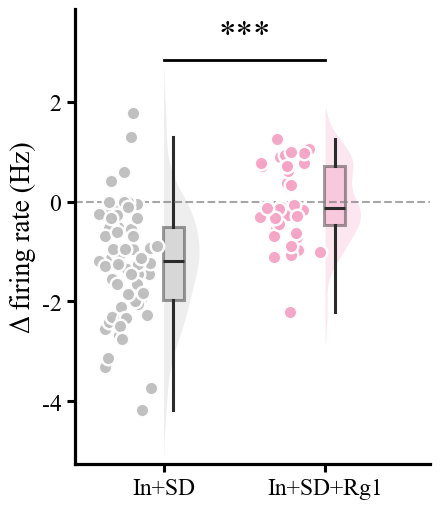

In [185]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde
import os

# =========================
# 半散点 + 半阴影箱线图
# Δ firing rate 两组比较
# =========================

# 数据
data_list = [data1, data2]
labels = [group1, group2]

# 颜色风格不变
group1_color = "#BDBDBD"   # In+SD，灰色
group2_color = "#F4A3C4"   # In+SD+Rg1，粉色
box_edge_color = "#2B2B2B"

color_list = [group1_color, group2_color]

# x 轴位置
x_positions = [1, 2]

plt.figure(figsize=(4.5, 5.2))
ax = plt.gca()

# 控制图形宽度
scatter_width = 0.10
violin_width = 0.22
box_width = 0.13
gap = 0.03

np.random.seed(1)

for x, data, color in zip(x_positions, data_list, color_list):

    # -------------------------
    # 左半边散点
    # -------------------------
    jitter = np.random.normal(
        loc=x - violin_width - gap,
        scale=scatter_width,
        size=len(data)
    )

    jitter = np.clip(
        jitter,
        x - violin_width - 0.18,
        x - gap
    )

    ax.scatter(
        jitter,
        data,
        s=95,
        color=color,
        edgecolor="white",
        linewidth=1.8,
        alpha=0.95,
        zorder=4
    )

    # -------------------------
    # 右半边阴影，小提琴密度
    # -------------------------
    data_std = np.std(data, ddof=1)

    y_min = data.min() - data_std * 0.8
    y_max = data.max() + data_std * 0.8

    y_grid = np.linspace(y_min, y_max, 300)

    if len(np.unique(data)) > 1:
        kde = gaussian_kde(data)
        density = kde(y_grid)
        density = density / density.max() * violin_width
    else:
        density = np.ones_like(y_grid) * violin_width * 0.3

    ax.fill_betweenx(
        y_grid,
        x,
        x + density,
        color=color,
        alpha=0.25,
        linewidth=0,
        zorder=1
    )

    # -------------------------
    # 右半边箱线图
    # -------------------------
    box = ax.boxplot(
        data,
        positions=[x + violin_width * 0.28],
        widths=box_width,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color=box_edge_color, linewidth=2.2),
        boxprops=dict(
            facecolor=color,
            alpha=0.45,
            color=box_edge_color,
            linewidth=2.2
        ),
        whiskerprops=dict(color=box_edge_color, linewidth=2.2),
        capprops=dict(color=box_edge_color, linewidth=0)
    )

    for cap in box["caps"]:
        cap.set_visible(False)

# =========================
# 添加 y=0 参考线
# =========================

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    alpha=0.7
)

# =========================
# 显著性标记
# =========================

all_data = np.concatenate([data1, data2])
y_top = np.max(all_data)
y_bottom = np.min(all_data)
y_range = y_top - y_bottom

y_sig = y_top + y_range * 0.18
text_y = y_sig + y_range * 0.03

ax.plot(
    [x_positions[0], x_positions[1]],
    [y_sig, y_sig],
    color="black",
    linewidth=2
)

if p_value < 0.001:
    sig_text = "***"
elif p_value < 0.01:
    sig_text = "**"
elif p_value < 0.05:
    sig_text = "*"
else:
    sig_text = "ns"

ax.text(
    np.mean(x_positions),
    text_y,
    sig_text,
    ha="center",
    va="bottom",
    fontsize=25,
    fontweight="regular"
)

# =========================
# 坐标轴设置
# =========================

ax.set_xticks(x_positions)
ax.set_xticklabels(
    labels,
    fontsize=19,
    fontweight="regular"
)

ax.set_ylabel(
    "Δ firing rate (Hz)",
    fontsize=20,
    fontweight="regular"
)

# y 轴范围
ax.set_ylim(
    y_bottom - y_range * 0.18,
    y_top + y_range * 0.35
)

ax.set_xlim(0.45, 2.65)

# =========================
# 美化
# =========================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(2.3)
ax.spines["bottom"].set_linewidth(2.3)

ax.tick_params(axis="both", width=2.2, length=6, labelsize=17)

plt.tight_layout()

# =========================
# 保存图片
# =========================

save_dir = r"D:\在体数据预处理\术前\neuronspiketimelfps\PSTH\两组"
os.makedirs(save_dir, exist_ok=True)

fig_save_path_png = os.path.join(save_dir, "Delta_firing_rate_InSD_vs_InSDRg1.png")
#fig_save_path_pdf = os.path.join(save_dir, "Delta_firing_rate_InSD_vs_InSDRg1.pdf")

plt.savefig(fig_save_path_png, dpi=300, bbox_inches="tight")
plt.savefig(fig_save_path_pdf, bbox_inches="tight")

print("图片已保存到：")
print(fig_save_path_png)
#print(fig_save_path_pdf)

plt.show()


四组Day7比较

In [37]:
import pandas as pd
import numpy as np
from scipy.stats import shapiro, levene, kruskal
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# =========================
# 读取四组统计 CSV
# =========================

file_path = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\四组箱式统计.csv"

df = pd.read_csv(file_path)

print(df.head())
print(df.columns)
print(df["Group"].unique())

# 固定四组顺序
group_order = ["Sham", "SD", "In", "In+SD"]

# 确保 Group 是字符串
df["Group"] = df["Group"].astype(str)

# 只保留这四组
df = df[df["Group"].isin(group_order)].copy()

# 设置分类顺序
df["Group"] = pd.Categorical(
    df["Group"],
    categories=group_order,
    ordered=True
)

# =========================
# 根据 Group 生成两个因素
# Factor 1: In
# Factor 2: SD
# =========================

df["In_factor"] = df["Group"].map({
    "Sham": "No_In",
    "SD": "No_In",
    "In": "In",
    "In+SD": "In"
})

df["SD_factor"] = df["Group"].map({
    "Sham": "No_SD",
    "SD": "SD",
    "In": "No_SD",
    "In+SD": "SD"
})

df["In_factor"] = pd.Categorical(
    df["In_factor"],
    categories=["No_In", "In"],
    ordered=True
)

df["SD_factor"] = pd.Categorical(
    df["SD_factor"],
    categories=["No_SD", "SD"],
    ordered=True
)

# =========================
# 提取每组 Δ firing rate
# =========================

group_data = {
    group: df[df["Group"] == group]["delta_hz"].dropna().values
    for group in group_order
}

# =========================
# 描述性统计
# =========================

print("\nDescriptive statistics:")
for group in group_order:
    data = group_data[group]
    print(
        f"{group}: n = {len(data)}, "
        f"mean ± SEM = {np.mean(data):.4f} ± {pd.Series(data).sem():.4f} Hz"
    )

# =========================
# 每组正态性检验
# =========================

print("\nShapiro-Wilk normality test:")
for group in group_order:
    data = group_data[group]

    if len(data) >= 3:
        shapiro_result = shapiro(data)
        print(
            f"{group}: W = {shapiro_result.statistic:.4f}, "
            f"p = {shapiro_result.pvalue:.4f}"
        )
    else:
        print(f"{group}: n < 3, Shapiro-Wilk test skipped")

# =========================
# 方差齐性检验
# =========================

levene_result = levene(
    group_data["Sham"],
    group_data["SD"],
    group_data["In"],
    group_data["In+SD"]
)

print("\nLevene test for equal variances:")
print(f"W = {levene_result.statistic:.4f}")
print(f"p = {levene_result.pvalue:.4f}")

# =========================
# Two-way ANOVA
# 因变量：delta_hz
# 因素：In_factor, SD_factor
# =========================

model = ols(
    "delta_hz ~ C(In_factor) * C(SD_factor)",
    data=df
).fit()

anova_table = sm.stats.anova_lm(
    model,
    typ=2
)

print("\nTwo-way ANOVA on Δ firing rate:")
print(anova_table)

# =========================
# Kruskal-Wallis 非参数整体检验，作为补充
# =========================

kruskal_result = kruskal(
    group_data["Sham"],
    group_data["SD"],
    group_data["In"],
    group_data["In+SD"]
)

print("\nKruskal-Wallis test across four groups:")
print(f"H = {kruskal_result.statistic:.4f}")
print(f"p = {kruskal_result.pvalue:.4f}")

# =========================
# Tukey HSD 多重比较
# 用于四组之间两两比较
# =========================

tukey = pairwise_tukeyhsd(
    endog=df["delta_hz"],
    groups=df["Group"],
    alpha=0.05
)

print("\nTukey HSD post-hoc test:")
print(tukey)

# 保存 Two-way ANOVA 结果
save_anova_path = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\四组_Two_way_ANOVA_results.csv"

anova_table.to_csv(
    save_anova_path,
    encoding="utf-8-sig"
)

print("\nTwo-way ANOVA 结果已保存到：")
print(save_anova_path)

# 保存 Tukey 结果
tukey_result_df = pd.DataFrame(
    data=tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

save_tukey_path = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\四组_Tukey_posthoc_results.csv"

tukey_result_df.to_csv(
    save_tukey_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nTukey 多重比较结果已保存到：")
print(save_tukey_path)


  Group mouse_id  unit_id  baseline_hz  stimulus_hz  delta_hz
0    In  Mouse_1  M1_U001     4.777760     6.555553  1.777793
1    In  Mouse_1  M1_U002     6.222225     6.055550 -0.166675
2    In  Mouse_1  M1_U003     4.555540     5.388885  0.833345
3    In  Mouse_2  M2_U001     5.800000     6.550000  0.750000
4    In  Mouse_2  M2_U002     5.800000     6.850000  1.050000
Index(['Group', 'mouse_id', 'unit_id', 'baseline_hz', 'stimulus_hz',
       'delta_hz'],
      dtype='str')
<StringArray>
['In', 'In+SD', 'Sham', 'SD']
Length: 4, dtype: str

Descriptive statistics:
Sham: n = 55, mean ± SEM = 0.1335 ± 0.1181 Hz
SD: n = 56, mean ± SEM = 0.0113 ± 0.0974 Hz
In: n = 33, mean ± SEM = 0.1280 ± 0.1542 Hz
In+SD: n = 45, mean ± SEM = -0.8660 ± 0.1366 Hz

Shapiro-Wilk normality test:
Sham: W = 0.9884, p = 0.8729
SD: W = 0.9797, p = 0.4626
In: W = 0.9741, p = 0.6024
In+SD: W = 0.9835, p = 0.7614

Levene test for equal variances:
W = 1.5023
p = 0.2154

Two-way ANOVA on Δ firing rate:
               

图片已保存到：
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\Delta_firing_rate_four_groupstwoway.png


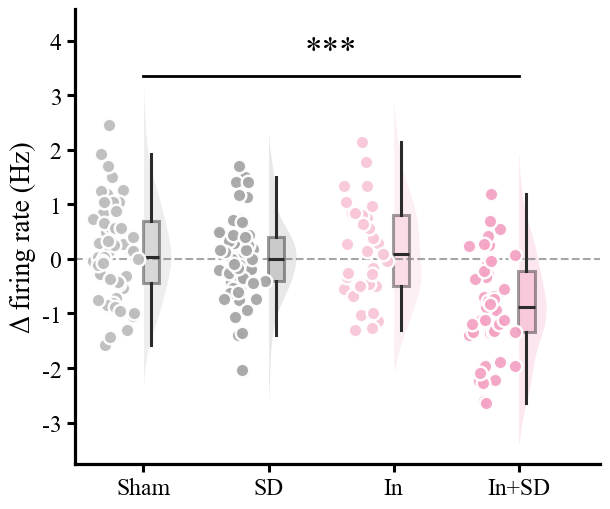

In [38]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde
import os

# =========================
# 半散点 + 半阴影箱线图
# 四组 Δ firing rate 比较
# =========================

# 固定顺序
group_order = ["Sham", "SD", "In", "In+SD"]

# 数据
data_list = [group_data[group] for group in group_order]
labels = group_order

# 颜色风格
# 这里保持之前灰色、粉色风格，并扩展到四组
color_list = [
    "#BDBDBD",   # Sham，灰色
    "#A6A6A6",   # SD，深一点灰色
    "#F8C6D8",   # In，浅粉色
    "#F4A3C4"    # In+SD，粉色
]

box_edge_color = "#2B2B2B"

# x 轴位置
x_positions = [1, 2, 3, 4]

plt.figure(figsize=(6.2, 5.2))
ax = plt.gca()

# 控制图形宽度
scatter_width = 0.10
violin_width = 0.22
box_width = 0.13
gap = 0.03

np.random.seed(1)

for x, data, color in zip(x_positions, data_list, color_list):

    # -------------------------
    # 左半边散点
    # -------------------------
    jitter = np.random.normal(
        loc=x - violin_width - gap,
        scale=scatter_width,
        size=len(data)
    )

    jitter = np.clip(
        jitter,
        x - violin_width - 0.18,
        x - gap
    )

    ax.scatter(
        jitter,
        data,
        s=95,
        color=color,
        edgecolor="white",
        linewidth=1.8,
        alpha=0.95,
        zorder=4
    )

    # -------------------------
    # 右半边阴影，小提琴密度
    # -------------------------
    data_std = np.std(data, ddof=1)

    if np.isnan(data_std) or data_std == 0:
        data_std = 0.1

    y_min = data.min() - data_std * 0.8
    y_max = data.max() + data_std * 0.8

    y_grid = np.linspace(y_min, y_max, 300)

    if len(np.unique(data)) > 1:
        kde = gaussian_kde(data)
        density = kde(y_grid)
        density = density / density.max() * violin_width
    else:
        density = np.ones_like(y_grid) * violin_width * 0.3

    ax.fill_betweenx(
        y_grid,
        x,
        x + density,
        color=color,
        alpha=0.25,
        linewidth=0,
        zorder=1
    )

    # -------------------------
    # 右半边箱线图
    # -------------------------
    box = ax.boxplot(
        data,
        positions=[x + violin_width * 0.28],
        widths=box_width,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color=box_edge_color, linewidth=2.2),
        boxprops=dict(
            facecolor=color,
            alpha=0.45,
            color=box_edge_color,
            linewidth=2.2
        ),
        whiskerprops=dict(color=box_edge_color, linewidth=2.2),
        capprops=dict(color=box_edge_color, linewidth=0)
    )

    for cap in box["caps"]:
        cap.set_visible(False)

# =========================
# y = 0 参考线
# =========================

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    alpha=0.7
)

# =========================
# 整体显著性标记
# =========================

all_data = np.concatenate(data_list)
y_top = np.max(all_data)
y_bottom = np.min(all_data)
y_range = y_top - y_bottom

if y_range == 0:
    y_range = 1

y_sig = y_top + y_range * 0.18
text_y = y_sig + y_range * 0.03

ax.plot(
    [x_positions[0], x_positions[-1]],
    [y_sig, y_sig],
    color="black",
    linewidth=2
)

#p_value = anova_result.pvalue
# 这里选择显示 In × SD 交互作用的显著性
p_value = anova_table.loc["C(In_factor):C(SD_factor)", "PR(>F)"]

if p_value < 0.001:
    sig_text = "***"
elif p_value < 0.01:
    sig_text = "**"
elif p_value < 0.05:
    sig_text = "*"
else:
    sig_text = "ns"

ax.text(
    np.mean([x_positions[0], x_positions[-1]]),
    text_y,
    sig_text,
    ha="center",
    va="bottom",
    fontsize=25,
    fontweight="regular"
)

# =========================
# 坐标轴设置
# =========================

ax.set_xticks(x_positions)
ax.set_xticklabels(
    labels,
    fontsize=19,
    fontweight="regular"
)

ax.set_ylabel(
    "Δ firing rate (Hz)",
    fontsize=20,
    fontweight="regular"
)

ax.set_ylim(
    y_bottom - y_range * 0.22,
    y_top + y_range * 0.42
)

ax.set_xlim(0.45, 4.65)

# =========================
# 美化
# =========================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(2.3)
ax.spines["bottom"].set_linewidth(2.3)

ax.tick_params(axis="both", width=2.2, length=6, labelsize=17)

plt.tight_layout()

# =========================
# 保存图片
# =========================

save_dir = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组"
os.makedirs(save_dir, exist_ok=True)

fig_save_path_png = os.path.join(save_dir, "Delta_firing_rate_four_groupstwoway.png")
#fig_save_path_pdf = os.path.join(save_dir, "Delta_firing_rate_four_groupstwoway.pdf")

plt.savefig(fig_save_path_png, dpi=300, bbox_inches="tight")
#plt.savefig(fig_save_path_pdf, bbox_inches="tight")

print("图片已保存到：")
print(fig_save_path_png)
#print(fig_save_path_pdf)

plt.show()


统计不同组别中出现“抑制型反应”的 PrL 兴奋性锥体神经元比例，也就是看在刺激期间，这些神经元有没有被疼痛刺激明显“压低放电”，抑制型反应神经元所占百分比

In [39]:
# -*- coding: utf-8 -*-

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


四组完整代码，抑制样反应比例

原始数据前 5 行：
  Group mouse_id  unit_id  baseline_hz  stimulus_hz  delta_hz
0    In  Mouse_1  M1_U001     4.777760     6.555553  1.777793
1    In  Mouse_1  M1_U002     6.222225     6.055550 -0.166675
2    In  Mouse_1  M1_U003     4.555540     5.388885  0.833345
3    In  Mouse_2  M2_U001     5.800000     6.550000  0.750000
4    In  Mouse_2  M2_U002     5.800000     6.850000  1.050000

数据列名：
['Group', 'mouse_id', 'unit_id', 'baseline_hz', 'stimulus_hz', 'delta_hz']

各组神经元数量：
Group
Sham     55
SD       56
In       33
In+SD    45
Name: count, dtype: int64

判断抑制型后的数据前 10 行：
   Group mouse_id  unit_id  delta_hz  is_inhibitory
78  Sham  Mouse_1  M1_U001 -1.041660           True
79  Sham  Mouse_1  M1_U002 -1.583327           True
80  Sham  Mouse_1  M1_U003  0.500010          False
81  Sham  Mouse_1  M1_U004  0.291662          False
82  Sham  Mouse_1  M1_U005 -0.541673           True
83  Sham  Mouse_1  M1_U006 -0.041655           True
84  Sham  Mouse_1  M1_U007 -0.999992           True
85  Sham  M

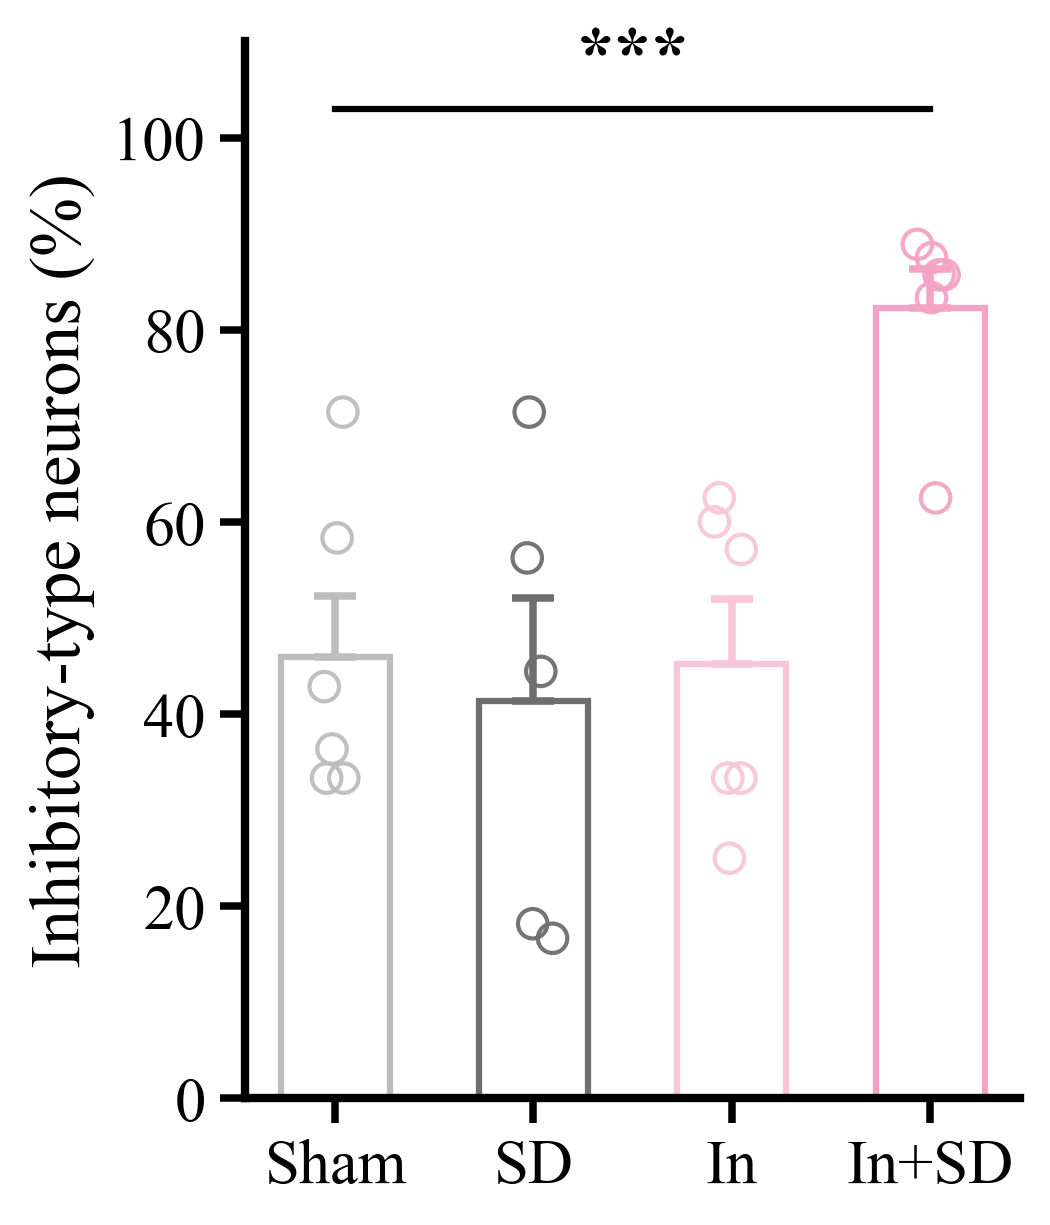


文件已保存：
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\各小鼠_抑制型神经元百分比.csv
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\各组_抑制型神经元百分比汇总.csv
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\抑制型神经元百分比_两两卡方检验.csv
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\抑制型神经元百分比_柱状散点图.png
D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组\抑制型神经元百分比_柱状散点图.pdf


In [40]:
# -*- coding: utf-8 -*-

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# =========================================================
# 1. 文件路径设置
# =========================================================

data_dir = r"D:\在体数据预处理\在体\neuronspiketimelfps\PSTH\四组"
file_name = "四组箱式统计.csv"

data_path = os.path.join(data_dir, file_name)

# 输出文件
output_csv_mouse = os.path.join(data_dir, "各小鼠_抑制型神经元百分比.csv")
output_csv_group = os.path.join(data_dir, "各组_抑制型神经元百分比汇总.csv")
output_csv_pair = os.path.join(data_dir, "抑制型神经元百分比_两两卡方检验.csv")
output_fig_png = os.path.join(data_dir, "抑制型神经元百分比_柱状散点图.png")
output_fig_pdf = os.path.join(data_dir, "抑制型神经元百分比_柱状散点图.pdf")


# =========================================================
# 2. 组别顺序、颜色、阈值参数
# =========================================================

# 组别顺序
group_order = ["Sham", "SD", "In", "In+SD"]



# 柱子颜色
group_colors = {
    "Sham": "white",    # Sham，灰色
    "SD": "white",      # SD，深一点灰色
    "In": "white",      # In，浅粉色
    "In+SD": "white"    # In+SD，粉色
}

# 散点边框颜色
dot_colors = {
    "Sham": "#BDBDBD",    # Sham，灰色
    "SD": "#6E6E6E",      # SD，深一点灰色
    "In": "#F8C6D8",      # In，浅粉色
    "In+SD": "#F4A3C4"    # In+SD，粉色
}

# 抑制型判断阈值
# 当前定义：delta_hz < 0 为抑制型反应神经元
inhibitory_threshold = 0


# =========================================================
# 3. 读取数据
# =========================================================

df = pd.read_csv(data_path)

print("原始数据前 5 行：")
print(df.head())

print("\n数据列名：")
print(df.columns.tolist())

# 检查必要列
required_cols = ["Group", "mouse_id", "unit_id", "delta_hz"]

for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"你的数据中缺少必要列：{col}")

# 只保留四组
df = df[df["Group"].isin(group_order)].copy()

# 设置组别顺序
df["Group"] = pd.Categorical(
    df["Group"],
    categories=group_order,
    ordered=True
)

df = df.sort_values(["Group", "mouse_id", "unit_id"])

print("\n各组神经元数量：")
print(df["Group"].value_counts().reindex(group_order))


# =========================================================
# 4. 根据 delta_hz 判断抑制型反应神经元
# =========================================================

df["is_inhibitory"] = df["delta_hz"] < inhibitory_threshold

print("\n判断抑制型后的数据前 10 行：")
print(df[["Group", "mouse_id", "unit_id", "delta_hz", "is_inhibitory"]].head(10))


# =========================================================
# 5. 计算每只小鼠的抑制型神经元百分比
# =========================================================

mouse_summary = (
    df.groupby(
        ["Group", "mouse_id"],
        observed=True
    )
    .agg(
        total_neurons=("unit_id", "count"),
        inhibitory_neurons=("is_inhibitory", "sum")
    )
    .reset_index()
)


mouse_summary["inhibitory_percent"] = (
    mouse_summary["inhibitory_neurons"] / mouse_summary["total_neurons"] * 100
)

# 删除无神经元的小鼠（避免出现 NaN）,否则柱状图没有边框和误差线
mouse_summary = mouse_summary.replace(
    [np.inf, -np.inf],
    np.nan
)
mouse_summary = mouse_summary.dropna(
    subset=["inhibitory_percent"]
)



mouse_summary["Group"] = pd.Categorical(
    mouse_summary["Group"],
    categories=group_order,
    ordered=True
)

mouse_summary = mouse_summary.sort_values(["Group", "mouse_id"])

print("\n每只小鼠抑制型神经元百分比：")
print(mouse_summary)

mouse_summary.to_csv(output_csv_mouse, index=False, encoding="utf-8-sig")


# =========================================================
# 6. 计算每组总体百分比
# =========================================================

group_summary = (
    df.groupby("Group", observed=False)
      .agg(
          total_neurons=("unit_id", "count"),
          inhibitory_neurons=("is_inhibitory", "sum")
      )
      .reset_index()
)

group_summary["inhibitory_percent"] = (
    group_summary["inhibitory_neurons"] / group_summary["total_neurons"] * 100
)

group_summary["Group"] = pd.Categorical(
    group_summary["Group"],
    categories=group_order,
    ordered=True
)

group_summary = group_summary.sort_values("Group")

print("\n每组总体抑制型神经元百分比：")
print(group_summary)

group_summary.to_csv(output_csv_group, index=False, encoding="utf-8-sig")


# =========================================================
# 7. 四组卡方检验
# =========================================================

contingency_table = []

for group in group_order:
    temp = df[df["Group"] == group]
    inhibitory_n = temp["is_inhibitory"].sum()
    non_inhibitory_n = len(temp) - inhibitory_n
    contingency_table.append([inhibitory_n, non_inhibitory_n])

contingency_table = np.array(contingency_table)

chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print("\n四组卡方检验结果：")
print("列含义：[抑制型神经元数量, 非抑制型神经元数量]")
print(contingency_table)
print(f"Chi-square = {chi2:.4f}")
print(f"p value = {p:.6f}")
print(f"dof = {dof}")


# =========================================================
# 8. 两两比较：In+SD vs Sham / SD / In
# =========================================================

pair_results = []

target_group = "Sham"

for compare_group in ["In+SD", "SD", "In"]:

    temp1 = df[df["Group"] == target_group]
    temp2 = df[df["Group"] == compare_group]

    table = np.array([
        [
            temp1["is_inhibitory"].sum(),
            len(temp1) - temp1["is_inhibitory"].sum()
        ],
        [
            temp2["is_inhibitory"].sum(),
            len(temp2) - temp2["is_inhibitory"].sum()
        ]
    ])

    chi2_pair, p_pair, dof_pair, expected_pair = stats.chi2_contingency(table)

    pair_results.append({
        "comparison": f"{target_group} vs {compare_group}",
        "inhibitory_target": temp1["is_inhibitory"].sum(),
        "non_inhibitory_target": len(temp1) - temp1["is_inhibitory"].sum(),
        "inhibitory_compare": temp2["is_inhibitory"].sum(),
        "non_inhibitory_compare": len(temp2) - temp2["is_inhibitory"].sum(),
        "chi2": chi2_pair,
        "p_value": p_pair
    })

pair_results = pd.DataFrame(pair_results)

print("\nSham 与其他组两两比较：")
print(pair_results)

pair_results.to_csv(output_csv_pair, index=False, encoding="utf-8-sig")


# =========================================================
# 9. 绘图参数
# =========================================================

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["axes.linewidth"] = 2.0
plt.rcParams["xtick.major.width"] = 1.8
plt.rcParams["ytick.major.width"] = 1.8
plt.rcParams["xtick.major.size"] = 6
plt.rcParams["ytick.major.size"] = 6
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42


# =========================================================


# =========================================================
# 10. 计算绘图用均值和 SEM
# =========================================================

x_positions = np.arange(len(group_order))

means = []
sems = []

for group in group_order:

    # 当前组所有小鼠百分比
    values = mouse_summary.loc[
        mouse_summary["Group"] == group,
        "inhibitory_percent"
    ].values

    # 删除 NaN
    values = values[~np.isnan(values)]

    # 防止空组
    if len(values) == 0:

        means.append(np.nan)
        sems.append(0)

        continue

    # 计算均值
    means.append(np.mean(values))

    # 计算 SEM
    if len(values) > 1:
        sems.append(stats.sem(values))
    else:
        sems.append(0)

means = np.array(means)
sems = np.array(sems)

print("\n绘图用均值：")

for g, m, s in zip(group_order, means, sems):

    print(
        f"{g}: "
        f"mean = {m:.2f}, "
        f"SEM = {s:.2f}"
    )


# =========================================================
# 11. 开始绘图
# =========================================================

fig, ax = plt.subplots(figsize=(3.6, 4.2), dpi=300)

bar_width = 0.55

# -------------------------
# 11.1 画柱子 + 只显示上半部分 SEM
# -------------------------

for i, group in enumerate(group_order):

    ax.bar(
        x_positions[i],
        means[i],
        width=bar_width,
        color=group_colors[group],  # 柱子内部填充颜色
        edgecolor=dot_colors[group],  # 柱子边框颜色
        linewidth=1.5,  # 柱子边框粗细
        alpha=1,   # 柱子透明度
        zorder=2
    )

    # 只显示上半部分误差线
    # yerr = [[下误差], [上误差]]
    # 下误差设为 0，上误差设为 SEM
    ax.errorbar(
        x_positions[i],
        means[i],
        yerr=np.array([[0], [sems[i]]]),
        fmt="none",
        ecolor=dot_colors[group],
        elinewidth=1.8,
        capsize=5,
        capthick=1.8,
        zorder=3
    )


# -------------------------
# 11.2 添加空心散点
# -------------------------

np.random.seed(123)

for i, group in enumerate(group_order):

    values = mouse_summary.loc[
        mouse_summary["Group"] == group,
        "inhibitory_percent"
    ].dropna().values

    # 散点左右轻微抖动
    jitter = np.random.uniform(-0.10, 0.10, size=len(values))

    ax.scatter(
        np.full(len(values), x_positions[i]) + jitter,
        values,
        s=50,
        facecolors="none",
        edgecolors=dot_colors[group],
        linewidths=1.,
        alpha=0.95,
        zorder=4
    )


# =========================================================
# 12. 可选：添加显著性横线
# =========================================================

def add_sig_bar(ax, x1, x2, y, text, line_height=2):
    """
    添加显著性横线
    x1, x2: 两组的 x 坐标
    y: 横线起始高度
    text: 星号文本，例如 '*', '**', '***'
    """
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + line_height, y + line_height, y],
        color="black",
        linewidth=1.5,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + line_height + 1.5,
        text,
        ha="center",
        va="bottom",
        fontsize=18,
        fontweight="bold"
    )

# 如果你要加显著性，取消下一行注释
# 假设在绘图部分调用
# 四组柱子绘制后，调用显著性标记
add_sig_bar(ax, 0, 3, 103, "***", line_height=0)



# =========================================================
# 13. 坐标轴设置
# =========================================================

ax.set_xticks(x_positions)
ax.set_xticklabels(group_order, fontsize=16)

ax.set_ylabel("Inhibitory-type neurons (%)", fontsize=17)
ax.set_xlabel("")

# Y 轴范围
ax.set_ylim(0, 110)

# Y 轴刻度
ax.set_yticks(np.arange(0, 101, 20))

ax.tick_params(axis="y", labelsize=15)
ax.tick_params(axis="x", labelsize=15)

# 去掉上边框和右边框
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# 加粗左轴和下轴
ax.spines["left"].set_linewidth(2.0)
ax.spines["bottom"].set_linewidth(2.0)

# 去掉背景网格
ax.grid(False)

plt.tight_layout()


# =========================================================
# 14. 保存图片
# =========================================================

plt.savefig(output_fig_png, dpi=300, bbox_inches="tight")
plt.savefig(output_fig_pdf, bbox_inches="tight")

plt.show()


# =========================================================
# 15. 输出保存位置
# =========================================================

print("\n文件已保存：")
print(output_csv_mouse)
print(output_csv_group)
print(output_csv_pair)
print(output_fig_png)
print(output_fig_pdf)


In [41]:
print(np.isnan(means))


[False False False False]


In [42]:
print(sems)
print(mouse_summary)

[ 6.38312569 10.68252738  6.70978239  4.02853248]
    Group mouse_id  total_neurons  inhibitory_neurons  inhibitory_percent
0    Sham  Mouse_1              7                   5           71.428571
1    Sham  Mouse_2              6                   2           33.333333
2    Sham  Mouse_3              7                   3           42.857143
3    Sham  Mouse_4             12                   7           58.333333
4    Sham  Mouse_5             12                   4           33.333333
5    Sham  Mouse_6             11                   4           36.363636
6      SD  Mouse_1              6                   1           16.666667
7      SD  Mouse_2              9                   4           44.444444
8      SD  Mouse_3             11                   2           18.181818
9      SD  Mouse_4             14                  10           71.428571
10     SD  Mouse_5             16                   9           56.250000
11     In  Mouse_1              3                   1         

In+SD  VS In+SD+Rg1 抑制样比例

原始数据前 5 行：
   Group mouse_id  unit_id  baseline_hz  stimulus_hz  delta_hz
0  In+SD  Mouse_1  M1_U001          6.9         5.45     -1.45
1  In+SD  Mouse_1  M1_U002          2.7         2.60     -0.10
2  In+SD  Mouse_1  M1_U003          5.9         5.80     -0.10
3  In+SD  Mouse_1  M1_U004          7.3         7.10     -0.20
4  In+SD  Mouse_1  M1_U005          5.6         5.55     -0.05

数据列名：
['Group', 'mouse_id', 'unit_id', 'baseline_hz', 'stimulus_hz', 'delta_hz']

各组神经元数量：
Group
In+SD        67
In+SD+Rg1    40
Name: count, dtype: int64

判断抑制型后的数据前 10 行：
   Group mouse_id  unit_id  delta_hz  is_inhibitory
0  In+SD  Mouse_1  M1_U001 -1.450000           True
1  In+SD  Mouse_1  M1_U002 -0.100000           True
2  In+SD  Mouse_1  M1_U003 -0.100000           True
3  In+SD  Mouse_1  M1_U004 -0.200000           True
4  In+SD  Mouse_1  M1_U005 -0.050000           True
5  In+SD  Mouse_1  M1_U006 -0.250000           True
6  In+SD  Mouse_2  M2_U001 -3.727273           True
7  In+SD  Mouse_2  M2

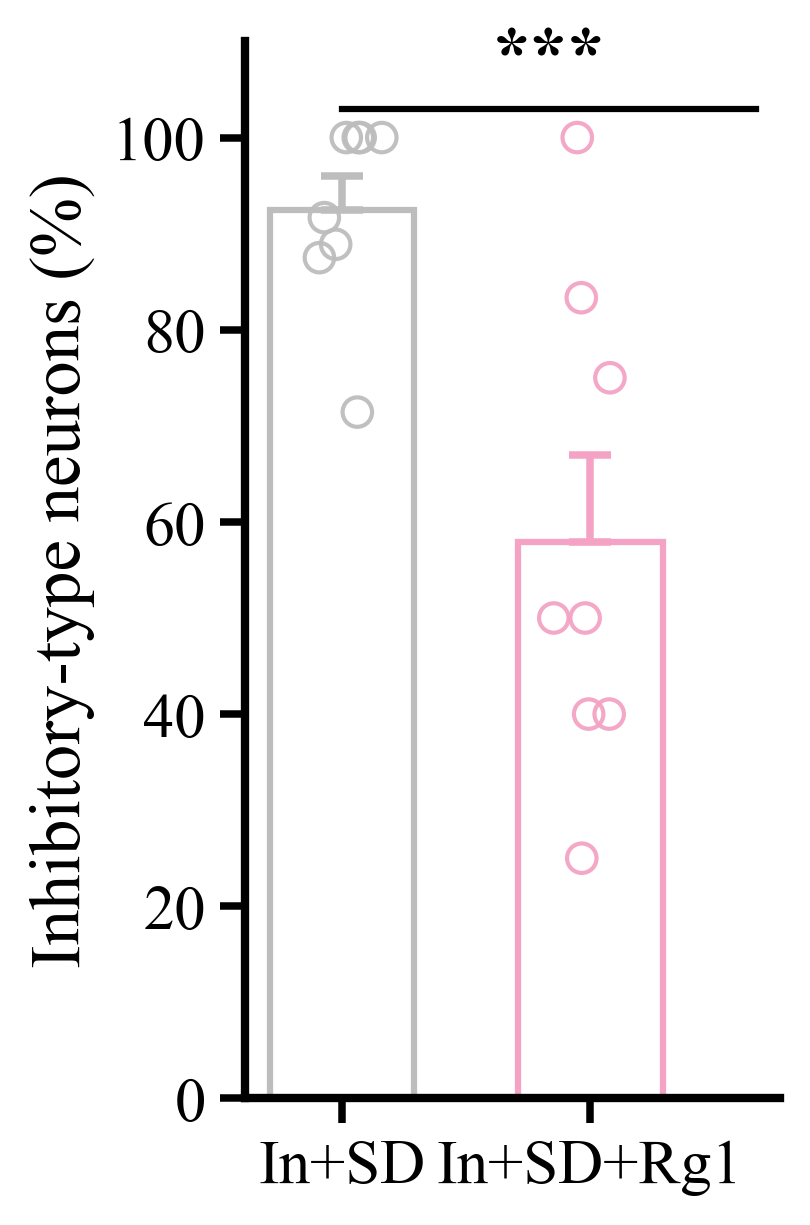


文件已保存：
D:\在体数据预处理\在体\neuronspiketimelfp\PSTH\两组\各小鼠_抑制型神经元百分比.csv
D:\在体数据预处理\在体\neuronspiketimelfp\PSTH\两组\各组_抑制型神经元百分比汇总.csv
D:\在体数据预处理\在体\neuronspiketimelfp\PSTH\两组\抑制型神经元百分比_两两卡方检验.csv
D:\在体数据预处理\在体\neuronspiketimelfp\PSTH\两组\抑制型神经元百分比_柱状散点图.png
D:\在体数据预处理\在体\neuronspiketimelfp\PSTH\两组\抑制型神经元百分比_柱状散点图.pdf


In [86]:
# -*- coding: utf-8 -*-

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# =========================================================
# 1. 文件路径设置
# =========================================================

data_dir = r"D:\在体数据预处理\在体\neuronspiketimelfp\PSTH\两组"
file_name = "两组箱式统计.csv"


data_path = os.path.join(data_dir, file_name)

# 输出文件
output_csv_mouse = os.path.join(data_dir, "各小鼠_抑制型神经元百分比.csv")
output_csv_group = os.path.join(data_dir, "各组_抑制型神经元百分比汇总.csv")
output_csv_pair = os.path.join(data_dir, "抑制型神经元百分比_两两卡方检验.csv")
output_fig_png = os.path.join(data_dir, "抑制型神经元百分比_柱状散点图.png")
output_fig_pdf = os.path.join(data_dir, "抑制型神经元百分比_柱状散点图.pdf")

# =========================================================
# 2. 组别顺序、颜色、阈值参数
# =========================================================

# 组别顺序
group_order = [
    "In+SD",
    "In+SD+Rg1"
]


# 柱子颜色
# 柱子颜色（全部空心）
group_colors = {
    "In+SD": "white",
    "In+SD+Rg1": "white"
}

# 散点和柱子边框颜色
dot_colors = {
    "In+SD": "#BDBDBD",       # 灰色
    "In+SD+Rg1": "#F4A3C4"   # 粉色
}


# 抑制型判断阈值
# 当前定义：delta_hz < 0 为抑制型反应神经元
inhibitory_threshold = 0

# =========================================================
# 3. 读取数据
# =========================================================

df = pd.read_csv(data_path)

print("原始数据前 5 行：")
print(df.head())

print("\n数据列名：")
print(df.columns.tolist())

# 检查必要列
required_cols = ["Group", "mouse_id", "unit_id", "delta_hz"]

for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"你的数据中缺少必要列：{col}")

# 只保留四组
df = df[df["Group"].isin(group_order)].copy()

# 设置组别顺序
df["Group"] = pd.Categorical(
    df["Group"],
    categories=group_order,
    ordered=True
)

df = df.sort_values(["Group", "mouse_id", "unit_id"])

print("\n各组神经元数量：")
print(df["Group"].value_counts().reindex(group_order))

# =========================================================
# 4. 根据 delta_hz 判断抑制型反应神经元
# =========================================================

df["is_inhibitory"] = df["delta_hz"] < inhibitory_threshold

print("\n判断抑制型后的数据前 10 行：")
print(df[["Group", "mouse_id", "unit_id", "delta_hz", "is_inhibitory"]].head(10))

# =========================================================
# 5. 计算每只小鼠的抑制型神经元百分比
# =========================================================

mouse_summary = (
    df.groupby(
        ["Group", "mouse_id"],
        observed=True
    )
    .agg(
        total_neurons=("unit_id", "count"),
        inhibitory_neurons=("is_inhibitory", "sum")
    )
    .reset_index()
)

mouse_summary["inhibitory_percent"] = (
        mouse_summary["inhibitory_neurons"] / mouse_summary["total_neurons"] * 100
)

# 删除无神经元的小鼠（避免出现 NaN）,否则柱状图没有边框和误差线
mouse_summary = mouse_summary.replace(
    [np.inf, -np.inf],
    np.nan
)
mouse_summary = mouse_summary.dropna(
    subset=["inhibitory_percent"]
)

mouse_summary["Group"] = pd.Categorical(
    mouse_summary["Group"],
    categories=group_order,
    ordered=True
)

mouse_summary = mouse_summary.sort_values(["Group", "mouse_id"])

print("\n每只小鼠抑制型神经元百分比：")
print(mouse_summary)

mouse_summary.to_csv(output_csv_mouse, index=False, encoding="utf-8-sig")

# =========================================================
# 6. 计算每组总体百分比
# =========================================================

group_summary = (
    df.groupby("Group", observed=False)
    .agg(
        total_neurons=("unit_id", "count"),
        inhibitory_neurons=("is_inhibitory", "sum")
    )
    .reset_index()
)

group_summary["inhibitory_percent"] = (
        group_summary["inhibitory_neurons"] / group_summary["total_neurons"] * 100
)

group_summary["Group"] = pd.Categorical(
    group_summary["Group"],
    categories=group_order,
    ordered=True
)

group_summary = group_summary.sort_values("Group")

print("\n每组总体抑制型神经元百分比：")
print(group_summary)

group_summary.to_csv(output_csv_group, index=False, encoding="utf-8-sig")

# =========================================================
# 7. 两组组卡方检验
# =========================================================
# 8. 两组卡方检验
# =========================================================

group1 = "In+SD"
group2 = "In+SD+Rg1"

temp1 = df[df["Group"] == group1]
temp2 = df[df["Group"] == group2]

table = np.array([
    [
        temp1["is_inhibitory"].sum(),
        len(temp1) - temp1["is_inhibitory"].sum()
    ],
    [
        temp2["is_inhibitory"].sum(),
        len(temp2) - temp2["is_inhibitory"].sum()
    ]
])

chi2_pair, p_pair, dof_pair, expected_pair = stats.chi2_contingency(table)

print("\n两组卡方检验：")
print(table)
print(f"Chi-square = {chi2_pair:.4f}")
print(f"p value = {p_pair:.6f}")

# =========================================================
# 9. 绘图参数
# =========================================================

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["axes.linewidth"] = 2.0
plt.rcParams["xtick.major.width"] = 1.8
plt.rcParams["ytick.major.width"] = 1.8
plt.rcParams["xtick.major.size"] = 6
plt.rcParams["ytick.major.size"] = 6
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# =========================================================


# =========================================================
# 10. 计算绘图用均值和 SEM
# =========================================================

x_positions = np.array([0, 0.6]) #两个柱状图之间近一点


means = []
sems = []

for group in group_order:

    # 当前组所有小鼠百分比
    values = mouse_summary.loc[
        mouse_summary["Group"] == group,
        "inhibitory_percent"
    ].values

    # 删除 NaN
    values = values[~np.isnan(values)]

    # 防止空组
    if len(values) == 0:
        means.append(np.nan)
        sems.append(0)

        continue

    # 计算均值
    means.append(np.mean(values))

    # 计算 SEM
    if len(values) > 1:
        sems.append(stats.sem(values))
    else:
        sems.append(0)

means = np.array(means)
sems = np.array(sems)

print("\n绘图用均值：")

for g, m, s in zip(group_order, means, sems):
    print(
        f"{g}: "
        f"mean = {m:.2f}, "
        f"SEM = {s:.2f}"
    )

# =========================================================
# 11. 开始绘图
# =========================================================

fig, ax = plt.subplots(figsize=(2.8, 4.2), dpi=300)

bar_width = 0.35

# -------------------------
# 11.1 画柱子 + 只显示上半部分 SEM
# -------------------------

for i, group in enumerate(group_order):
    ax.bar(
        x_positions[i],
        means[i],
        width=bar_width,
        color=group_colors[group],  # 柱子内部填充颜色
        edgecolor=dot_colors[group],  # 柱子边框颜色
        linewidth=1.5,  # 柱子边框粗细
        alpha=1,  # 柱子透明度
        zorder=2
    )

    # 只显示上半部分误差线
    # yerr = [[下误差], [上误差]]
    # 下误差设为 0，上误差设为 SEM
    ax.errorbar(
        x_positions[i],
        means[i],
        yerr=np.array([[0], [sems[i]]]),
        fmt="none",
        ecolor=dot_colors[group],
        elinewidth=1.8,
        capsize=5,
        capthick=1.8,
        zorder=3
    )

# -------------------------
# 11.2 添加空心散点
# -------------------------

np.random.seed(123)

for i, group in enumerate(group_order):
    values = mouse_summary.loc[
        mouse_summary["Group"] == group,
        "inhibitory_percent"
    ].dropna().values

    # 散点左右轻微抖动
    jitter = np.random.uniform(-0.10, 0.10, size=len(values))

    ax.scatter(
        np.full(len(values), x_positions[i]) + jitter,
        values,
        s=50,
        facecolors="none",
        edgecolors=dot_colors[group],
        linewidths=1.,
        alpha=0.95,
        zorder=4
    )


# =========================================================
# 12. 可选：添加显著性横线
# =========================================================

def add_sig_bar(ax, x1, x2, y, text, line_height=2):
    """
    添加显著性横线
    x1, x2: 两组的 x 坐标
    y: 横线起始高度
    text: 星号文本，例如 '*', '**', '***'
    """
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + line_height, y + line_height, y],
        color="black",
        linewidth=1.5,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + line_height + 1.5,
        text,
        ha="center",
        va="bottom",
        fontsize=18,
        fontweight="bold"
    )


# 如果你要加显著性，取消下一行注释
# 假设在绘图部分调用
# 四组柱子绘制后，调用显著性标记
add_sig_bar(ax, 0, 1, 103, "***", line_height=0)

# =========================================================
# 13. 坐标轴设置
# =========================================================

ax.set_xticks(x_positions)
ax.set_xticklabels(group_order, fontsize=16)

ax.set_ylabel("Inhibitory-type neurons (%)", fontsize=17)
ax.set_xlabel("")

# Y 轴范围
ax.set_ylim(0, 110)

# Y 轴刻度
ax.set_yticks(np.arange(0, 101, 20))

ax.tick_params(axis="y", labelsize=15)
ax.tick_params(axis="x", labelsize=15)

# 去掉上边框和右边框
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# 加粗左轴和下轴
ax.spines["left"].set_linewidth(2.0)
ax.spines["bottom"].set_linewidth(2.0)

# 去掉背景网格
ax.grid(False)

plt.tight_layout()

# =========================================================
# 14. 保存图片
# =========================================================

plt.savefig(output_fig_png, dpi=300, bbox_inches="tight")
plt.savefig(output_fig_pdf, bbox_inches="tight")

plt.show()

# =========================================================
# 15. 输出保存位置
# =========================================================

print("\n文件已保存：")
print(output_csv_mouse)
print(output_csv_group)
print(output_csv_pair)
print(output_fig_png)
print(output_fig_pdf)
